# BirdCLEF 2026 — Perch v2 embeddings + full-recording MIL
This notebook restores the last working recording-level MIL baseline: all
nonoverlapping five-second windows, padded bags, boolean masks and per-class
masked maximum pooling. Audio labels apply to the entire recording. Annotated
soundscapes remain singleton bags; unannotated intervals are excluded.

The new frozen window encoder is Google Perch v2, a bioacoustic pretrained model.
Sections 5–6 read the original audio once and save 1536-dimensional embeddings,
not spectrograms. The trainable head learns on these cached embeddings. This is
transfer learning with a frozen encoder, not end-to-end fine-tuning/distillation.
Existing spectrogram exports cannot be supplied as Perch input.

Kaggle: attach the competition dataset, enable GPU, and attach the Google Perch
TensorFlow2 perch_v2 version 2 model, or enable Internet for kagglehub download.
Set PERCH_MODEL_PATH below if your attached SavedModel has a different path.
No pip upgrades/downgrades are performed. A model preflight runs before extraction.
For a pilot, set PILOT_FILES_PER_SOURCE=200 in Section 5–6. Full training requires
PILOT_FILES_PER_SOURCE=None. Initial settings: 8 epochs, bag batch size 2. The last continuation cell is
disabled by default. Checkpoints from the old CNN cannot initialize this new head.

References:
- https://www.kaggle.com/models/google/bird-vocalization-classifier/tensorFlow2/perch_v2/2
- https://github.com/google-research/perch

IMPORTANT: Perch pretraining may overlap public competition recordings. The local
split prevents recording leakage within this notebook, not external pretraining
overlap. Keep this limitation in the report. Test is never used for model selection.

**Contents:** 1 Setup · 2 Load and validate the data · 3 Exploration · 4 Label targets · 5 Perch encoder and file selection · 6 Embedding export · 7 Splits · 8 Loader · 9 Handoff check · 10 Handoff notes · 11 Training · 12 Validation report

## 1. Setup and configuration
All imports, seeds and shared settings.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # Must be set before TensorFlow is imported.

import ast
import hashlib2
import json
import math
import shutil
import sys
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter
from uuid import uuid4

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import tensorflow as tf
from IPython.display import Audio, display
from sklearn.metrics import (
    average_precision_score, precision_recall_fscore_support, roc_auc_score,
)
from tqdm.auto import tqdm

print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {tf.config.list_physical_devices('GPU')}")

# ============================================================
# CONFIGURATION
# ============================================================

# Reproducibility: seeds Python, NumPy and TensorFlow.
SEED = 42
DETERMINISTIC = True
tf.keras.utils.set_random_seed(SEED)
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()

# Dataset split ratios
AUDIO_TRAIN_RATIO = 0.80
AUDIO_VAL_RATIO = 0.10
AUDIO_TEST_RATIO = 0.10

SOUNDSCAPE_TRAIN_RATIO = 0.70
SOUNDSCAPE_VAL_RATIO = 0.15
SOUNDSCAPE_TEST_RATIO = 0.15

# Audio windows
SAMPLE_RATE = 32000
WINDOW_SECONDS = 5.0
WINDOW_SAMPLES = int(SAMPLE_RATE * WINDOW_SECONDS)

# Mel spectrogram settings. Only used for the example plot in Section 3.4;
# the model itself uses Perch embeddings.
N_MELS = 64
FFT_LENGTH = 2048
FRAME_LENGTH = 2048
HOP_LENGTH = 640  # 20 ms at 32 kHz
MEL_LOWER_HZ = 20.0
MEL_UPPER_HZ = 14000.0

# Bags per batch for the Section 8 loaders. Full recordings can be long;
# raise only if memory allows.
BATCH_SIZE = 1

# Validate configuration
assert np.isclose(
    AUDIO_TRAIN_RATIO + AUDIO_VAL_RATIO + AUDIO_TEST_RATIO, 1.0
), "Audio split ratios must sum to 1."
assert np.isclose(
    SOUNDSCAPE_TRAIN_RATIO + SOUNDSCAPE_VAL_RATIO + SOUNDSCAPE_TEST_RATIO, 1.0
), "Soundscape split ratios must sum to 1."
assert 0 <= MEL_LOWER_HZ < MEL_UPPER_HZ <= SAMPLE_RATE / 2
assert FRAME_LENGTH <= FFT_LENGTH and WINDOW_SAMPLES >= FRAME_LENGTH
assert BATCH_SIZE >= 1

print("Configuration initialized successfully.")
print(f"Samples per window: {WINDOW_SAMPLES:,}")

ModuleNotFoundError: No module named 'hashlib2'

## 2. Load and validate the data
Loads the three CSV files and stops with an error on missing columns or values, unknown labels, duplicates, invalid 5-second intervals, or missing audio files.

In [2]:
# ============================================================
# 2.0 - LOCATE THE DATASET
# ============================================================

OUTPUT_DIR = Path("/kaggle/working")

DATA_DIR = Path("/kaggle/input/competitions/birdclef-2026")

if not (DATA_DIR / "train.csv").is_file():
    raise FileNotFoundError(
        f"train.csv not found in: {DATA_DIR}\n"
        "Set DATA_DIR to the competition folder shown in the Kaggle Input panel."
    )

print(f"Dataset directory: {DATA_DIR}")

# ============================================================
# BASIC VALIDATION
# ============================================================

required_files = [
    "train.csv",
    "taxonomy.csv",
    "train_soundscapes_labels.csv",
]

required_directories = [
    "train_audio",
    "train_soundscapes",
]

missing = [
    str(DATA_DIR / filename)
    for filename in required_files
    if not (DATA_DIR / filename).is_file()
]

missing.extend(
    str(DATA_DIR / dirname)
    for dirname in required_directories
    if not (DATA_DIR / dirname).is_dir()
)

if missing:
    raise FileNotFoundError(
        "Missing dataset components:\n" + "\n".join(missing)
    )
    
print("\nAll required dataset components are available.")

# ============================================================
# 2.1 - LOAD DATASETS AND VALIDATE REQUIRED COLUMNS
# ============================================================

train_df = pd.read_csv(
    DATA_DIR / "train.csv",
    dtype={
        "filename": "string",
        "primary_label": "string",
        "secondary_labels": "string",
    },
)

taxonomy_df = pd.read_csv(
    DATA_DIR / "taxonomy.csv",
    dtype={"primary_label": "string"},
)

soundscape_df = pd.read_csv(
    DATA_DIR / "train_soundscapes_labels.csv",
    dtype={
        "filename": "string",
        "start": "string",
        "end": "string",
        "primary_label": "string",
    },
)

required_columns = {
    "train": {"filename", "primary_label", "secondary_labels"},
    "taxonomy": {"primary_label"},
    "soundscape": {"filename", "start", "end", "primary_label"},
}

tables = {
    "train": train_df,
    "taxonomy": taxonomy_df,
    "soundscape": soundscape_df,
}

for name, frame in tables.items():
    missing = required_columns[name] - set(frame.columns)

    if missing:
        raise ValueError(
            f"{name}: missing required columns: {sorted(missing)}"
        )

    if frame.empty:
        raise ValueError(f"{name}: the table is empty.")

print("2.1 OK: datasets loaded and required columns verified.")


# ============================================================
# 2.2 - VALIDATE REQUIRED VALUES AND CLASS LABELS
# ============================================================

def require_nonempty(frame, columns, name):
    """Reject missing or whitespace-only required values."""
    for column in columns:
        values = frame[column].astype("string").str.strip()
        invalid = values.isna() | values.eq("").fillna(False)

        if invalid.any():
            rows = frame.index[invalid].tolist()[:5]
            raise ValueError(
                f"{name}: empty '{column}' values at rows {rows}."
            )

        frame[column] = values


def parse_label_field(value, list_format=False):
    """Parse labels without silently discarding malformed values."""
    if pd.isna(value) or str(value).strip() == "":
        if list_format:
            return []
        raise ValueError("An annotation label field is empty.")

    text = str(value).strip()

    if list_format or text.startswith("["):
        try:
            labels = ast.literal_eval(text)
        except (ValueError, SyntaxError) as error:
            raise ValueError(
                f"Invalid label list: {text!r}"
            ) from error

        if not isinstance(labels, (list, tuple)):
            raise ValueError(f"Expected a label list: {text!r}")
    else:
        labels = text.split(";")

    labels = [str(label).strip() for label in labels]

    if any(not label for label in labels):
        raise ValueError(f"Empty label inside field: {text!r}")

    return list(dict.fromkeys(labels))


require_nonempty(train_df, ["filename", "primary_label"], "train")
require_nonempty(taxonomy_df, ["primary_label"], "taxonomy")
require_nonempty(
    soundscape_df,
    ["filename", "start", "end", "primary_label"],
    "soundscape",
)

# Normalize path separators.
for frame in [train_df, soundscape_df]:
    frame["filename"] = frame["filename"].str.replace(
        "\\", "/", regex=False
    )

known_labels = set(taxonomy_df["primary_label"])

secondary_lists = []
for row_index, value in train_df["secondary_labels"].items():
    try:
        secondary_lists.append(
            parse_label_field(value, list_format=True)
        )
    except ValueError as error:
        raise ValueError(
            f"train: invalid secondary_labels at row {row_index}: {error}"
        ) from error

soundscape_lists = []
for row_index, value in soundscape_df["primary_label"].items():
    try:
        labels = parse_label_field(value)
        if not labels:
            raise ValueError("Annotation has no class labels.")
        soundscape_lists.append(labels)
    except ValueError as error:
        raise ValueError(
            f"soundscape: invalid labels at row {row_index}: {error}"
        ) from error

used_labels = set(train_df["primary_label"])
used_labels.update(
    label for labels in secondary_lists for label in labels
)
used_labels.update(
    label for labels in soundscape_lists for label in labels
)

unknown_labels = used_labels - known_labels

if unknown_labels:
    raise ValueError(
        f"Labels missing from taxonomy: {sorted(unknown_labels)}"
    )

# Keep CSV-compatible strings for compatibility with later blocks.
train_df["secondary_labels"] = [
    repr(sorted(labels)) for labels in secondary_lists
]
soundscape_df["primary_label"] = [
    ";".join(sorted(labels)) for labels in soundscape_lists
]

print("2.2 OK: required values and class labels verified.")


# ============================================================
# 2.3 - REMOVE DUPLICATES AND VALIDATE ANNOTATION INTERVALS
# ============================================================

for name in tables:
    tables[name] = tables[name].drop_duplicates().reset_index(drop=True)

train_df = tables["train"]
taxonomy_df = tables["taxonomy"]
soundscape_df = tables["soundscape"]

if train_df["filename"].duplicated().any():
    repeated = train_df.loc[
        train_df["filename"].duplicated(keep=False), "filename"
    ].unique()[:5]

    raise ValueError(
        f"train: multiple distinct rows reference the same file: "
        f"{repeated.tolist()}"
    )

if taxonomy_df["primary_label"].duplicated().any():
    repeated = taxonomy_df.loc[
        taxonomy_df["primary_label"].duplicated(keep=False),
        "primary_label",
    ].unique()[:5]

    raise ValueError(
        f"taxonomy: conflicting rows for class identifiers: "
        f"{repeated.tolist()}"
    )


def parse_time_seconds(value):
    """Accept numeric seconds or HH:MM:SS timestamps."""
    try:
        seconds = float(value)
    except (TypeError, ValueError):
        try:
            seconds = pd.to_timedelta(str(value)).total_seconds()
        except (TypeError, ValueError, OverflowError) as error:
            raise ValueError(
                f"Invalid annotation time: {value!r}"
            ) from error

    if not np.isfinite(seconds):
        raise ValueError(f"Nonfinite annotation time: {value!r}")

    return seconds


intervals = soundscape_df.copy()
intervals["start"] = intervals["start"].map(parse_time_seconds)
intervals["end"] = intervals["end"].map(parse_time_seconds)

invalid = (
    (intervals["start"] < 0)
    | (intervals["end"] <= intervals["start"])
    | ~np.isclose(
        intervals["end"] - intervals["start"],
        WINDOW_SECONDS,
        atol=1e-6,
        rtol=0,
    )
)

if invalid.any():
    examples = intervals.loc[
        invalid, ["filename", "start", "end"]
    ].head(5)

    raise ValueError(
        f"Invalid annotation intervals:\n{examples.to_string(index=False)}"
    )


def merge_interval_labels(values):
    """Union labels only within the same recording and interval."""
    labels = {
        label
        for value in values
        for label in value.split(";")
    }
    return ";".join(sorted(labels))


soundscape_df = (
    intervals
    .groupby(["filename", "start", "end"], as_index=False, sort=True)
    .agg(primary_label=("primary_label", merge_interval_labels))
)

# Preserve timestamp strings expected by the existing exploration cells.
for column in ["start", "end"]:
    soundscape_df[column] = soundscape_df[column].map(
        lambda seconds: str(pd.to_timedelta(seconds, unit="s"))
    )

print("2.3 OK: duplicates resolved and annotation intervals verified.")


# ============================================================
# 2.4 - MATCH ANNOTATIONS TO AUDIO FILES
# ============================================================

audio_dir = DATA_DIR / "train_audio"
soundscape_dir = DATA_DIR / "train_soundscapes"

# Verify every referenced file; no recursive directory scan.
for name, frame, directory in [
    ("train", train_df, audio_dir),
    ("soundscape", soundscape_df, soundscape_dir),
]:
    missing = [
        filename
        for filename in frame["filename"].unique()
        if not (directory / filename).is_file()
    ]

    if missing:
        raise FileNotFoundError(
            f"{name}: {len(missing)} referenced files are missing. "
            f"Examples: {missing[:5]}"
        )

# Read each referenced soundscape header once.
soundscape_info = {}

for filename in soundscape_df["filename"].unique():
    try:
        info = sf.info(str(soundscape_dir / filename))
    except Exception as error:
        raise RuntimeError(
            f"Cannot read soundscape header: {filename}"
        ) from error

    if info.samplerate <= 0 or info.frames <= 0:
        raise ValueError(f"Invalid soundscape header: {filename}")

    soundscape_info[filename] = info

for row in soundscape_df.itertuples(index=False):
    info = soundscape_info[row.filename]

    start_frame = round(parse_time_seconds(row.start) * info.samplerate)
    end_frame = round(parse_time_seconds(row.end) * info.samplerate)

    if not (0 <= start_frame < end_frame <= info.frames):
        raise ValueError(
            f"Annotation outside recording: {row.filename}, "
            f"{row.start}–{row.end}"
        )

# Keep variables required by the current downstream blocks.
train_clean_df = train_df.copy()
taxonomy_clean_df = taxonomy_df.copy()
soundscape_clean_df = soundscape_df.copy()

print("2.4 OK: referenced audio files and annotation boundaries verified.")

Dataset directory: /kaggle/input/competitions/birdclef-2026

All required dataset components are available.
2.1 OK: datasets loaded and required columns verified.
2.2 OK: required values and class labels verified.
2.3 OK: duplicates resolved and annotation intervals verified.
2.4 OK: referenced audio files and annotation boundaries verified.


## 3. Exploratory data analysis
Dataset counts, class balance, ratings, species per soundscape interval, recording durations (200-file sample), and one example recording.

,Data,Count
0,Individual audio recordings,35549
1,Annotated soundscape recordings,66
2,Annotated soundscape intervals,739
3,Taxonomy classes,234


Represented primary classes: 206
Minimum recordings per class: 1
Median recordings per class: 125.0
Maximum recordings per class: 499


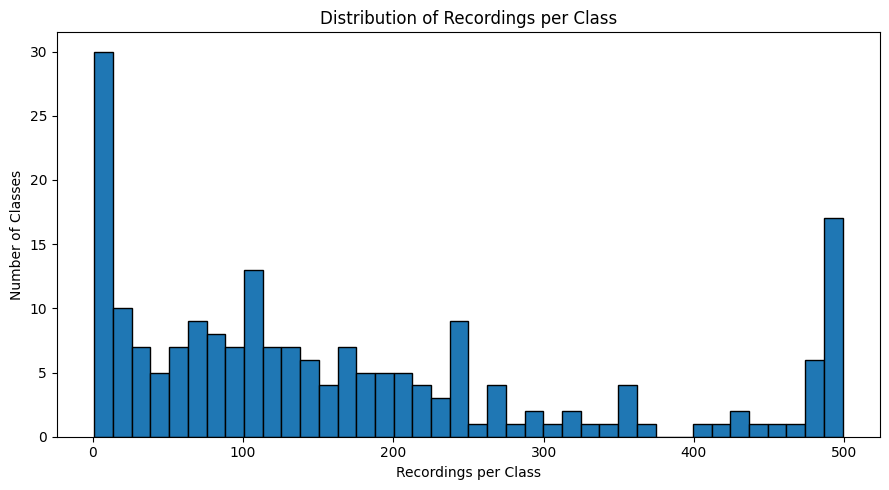

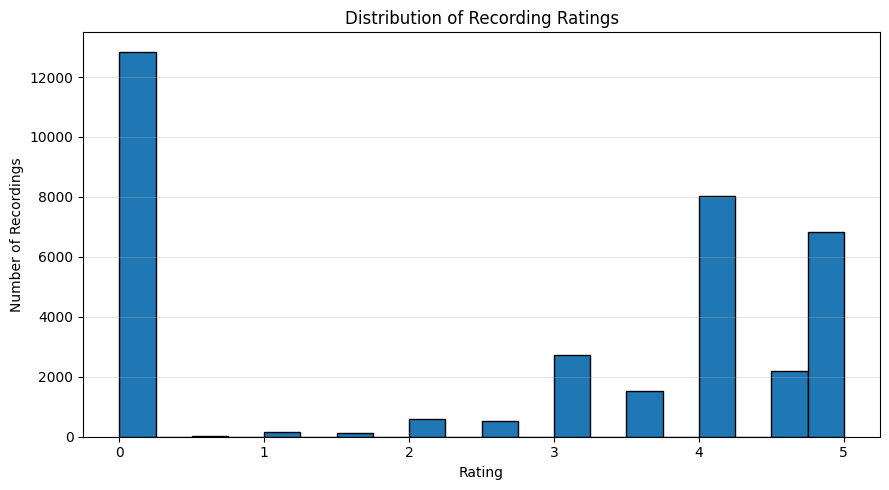

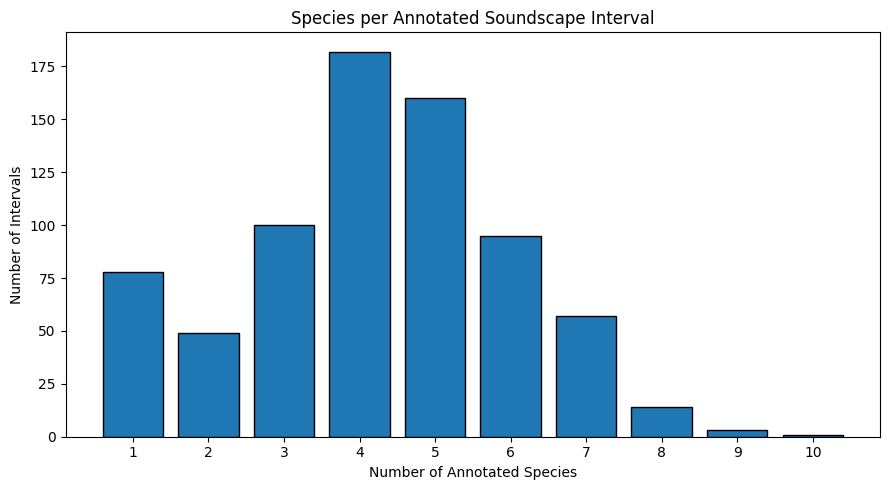

Recordings sampled for duration analysis: 200


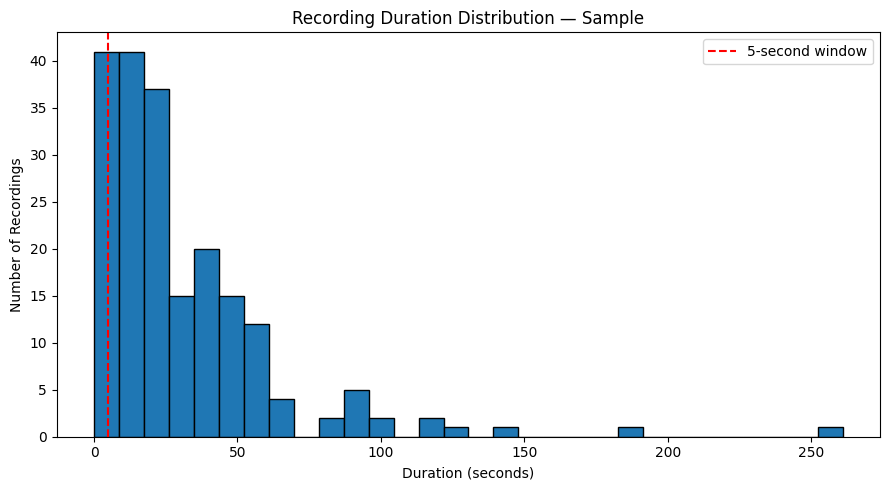

Filename: purjay1/XC299441.ogg
Primary label: purjay1
Excerpt duration: 5.00 seconds
Sample rate: 32,000 Hz


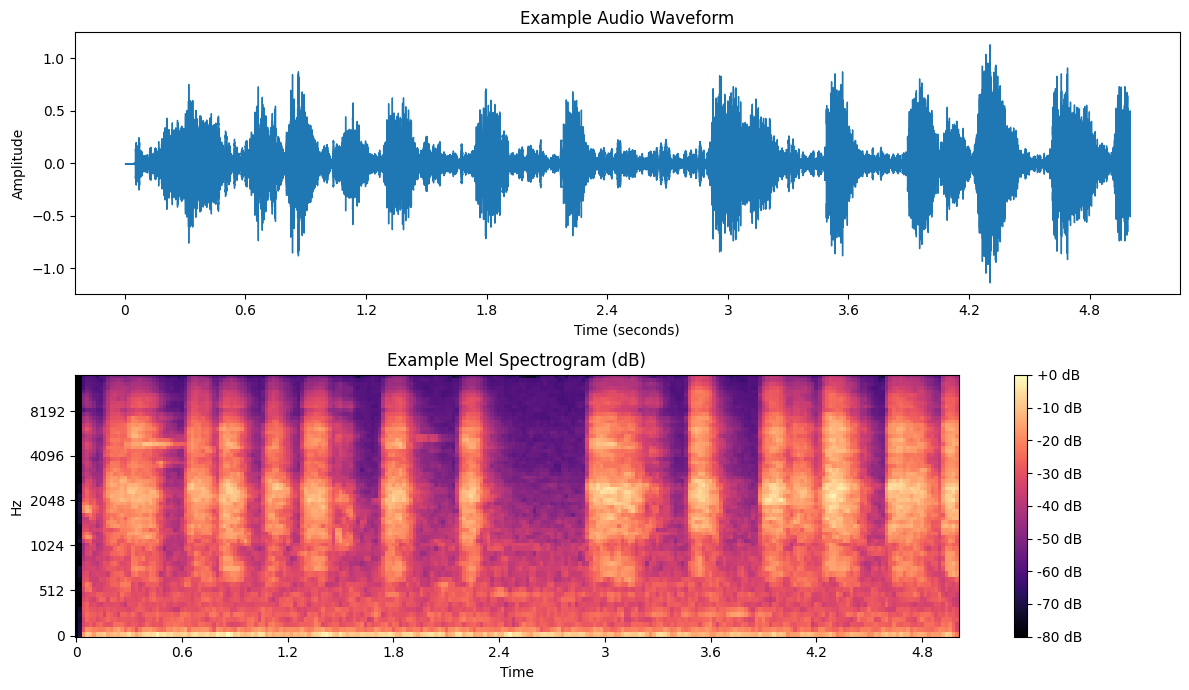

In [3]:
# ============================================================
# 3.1 - DATASET OVERVIEW AND CLASS DISTRIBUTION
# ============================================================

overview = pd.DataFrame({
    "Data": [
        "Individual audio recordings",
        "Annotated soundscape recordings",
        "Annotated soundscape intervals",
        "Taxonomy classes",
    ],
    "Count": [
        len(train_df),
        soundscape_clean_df["filename"].nunique(),
        len(soundscape_clean_df),
        taxonomy_df["primary_label"].nunique(),
    ],
})

display(overview)

class_counts = train_df["primary_label"].value_counts()

print("Represented primary classes:", len(class_counts))
print("Minimum recordings per class:", class_counts.min())
print("Median recordings per class:", class_counts.median())
print("Maximum recordings per class:", class_counts.max())

plt.figure(figsize=(9, 5))
plt.hist(class_counts.values, bins=40, edgecolor="black")
plt.title("Distribution of Recordings per Class")
plt.xlabel("Recordings per Class")
plt.ylabel("Number of Classes")
plt.tight_layout()
plt.show()


# ============================================================
# 3.2 - RECORDING RATINGS AND SOUNDSCAPE LABEL COUNTS
# ============================================================

if "rating" in train_df.columns:
    ratings = pd.to_numeric(train_df["rating"], errors="coerce")

    plt.figure(figsize=(9, 5))
    plt.hist(ratings.dropna(), bins=20, edgecolor="black")
    plt.title("Distribution of Recording Ratings")
    plt.xlabel("Rating")
    plt.ylabel("Number of Recordings")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

# Reuse the label parser defined in Section 2.
species_counts = soundscape_clean_df["primary_label"].map(
    lambda value: len(set(parse_label_field(value)))
)

count_distribution = species_counts.value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(
    count_distribution.index,
    count_distribution.values,
    edgecolor="black",
)
plt.xticks(count_distribution.index)
plt.title("Species per Annotated Soundscape Interval")
plt.xlabel("Number of Annotated Species")
plt.ylabel("Number of Intervals")
plt.tight_layout()
plt.show()


# ============================================================
# 3.3 - RECORDING DURATION DISTRIBUTION
# ============================================================

# Use a reproducible sample to avoid reading every audio header.
DURATION_SAMPLE_SIZE = 200

audio_sample = train_df.sample(
    n=min(DURATION_SAMPLE_SIZE, len(train_df)),
    random_state=SEED,
).copy()


def get_audio_duration(path):
    """Read recording duration without decoding the waveform."""
    info = sf.info(str(path))
    return info.frames / info.samplerate


audio_sample["duration_seconds"] = audio_sample["filename"].map(
    lambda filename: get_audio_duration(audio_dir / filename)
)

print(f"Recordings sampled for duration analysis: {len(audio_sample)}")

plt.figure(figsize=(9, 5))
plt.hist(
    audio_sample["duration_seconds"],
    bins=30,
    edgecolor="black",
)
plt.axvline(
    WINDOW_SECONDS,
    color="red",
    linestyle="--",
    label=f"{WINDOW_SECONDS:g}-second window",
)
plt.title("Recording Duration Distribution — Sample")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Recordings")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3.4 - EXAMPLE AUDIO, WAVEFORM AND MEL SPECTROGRAM
# ============================================================

example = audio_sample.iloc[0]
audio_path = audio_dir / example["filename"]

# Show the same excerpt in the player and both plots.
waveform, sr = librosa.load(
    audio_path,
    sr=SAMPLE_RATE,
    duration=WINDOW_SECONDS,
    mono=True,
)

print("Filename:", example["filename"])
print("Primary label:", example["primary_label"])
print(f"Excerpt duration: {len(waveform) / sr:.2f} seconds")
print(f"Sample rate: {sr:,} Hz")

display(Audio(waveform, rate=sr))

# Illustrative only; the model uses Perch embeddings (Sections 5-6).
mel_power = librosa.feature.melspectrogram(
    y=waveform,
    sr=sr,
    n_fft=FFT_LENGTH,
    win_length=FRAME_LENGTH,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    fmin=MEL_LOWER_HZ,
    fmax=MEL_UPPER_HZ,
    power=2.0,
)

mel_db = librosa.power_to_db(mel_power, ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

librosa.display.waveshow(waveform, sr=sr, ax=axes[0])
axes[0].set_title("Example Audio Waveform")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")

image = librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel",
    fmin=MEL_LOWER_HZ,
    fmax=MEL_UPPER_HZ,
    ax=axes[1],
)
axes[1].set_title("Example Mel Spectrogram (dB)")
fig.colorbar(image, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()

## 4. Class mapping and label targets
Encodes primary and secondary labels as separate 0/1 vectors in taxonomy order, verifies them, and saves them to `labels/`.

In [4]:
# ============================================================
# 4.1 - CLASS MAPPING AND TARGET ENCODING
# ============================================================

class_names = taxonomy_clean_df["primary_label"].tolist()
N_CLASSES = len(class_names)

class_to_idx = {
    label: index for index, label in enumerate(class_names)
}
idx_to_class = {
    index: label for index, label in enumerate(class_names)
}


def encode_labels(labels, class_to_idx, n_classes):
    """Encode labels using the shared taxonomy order."""
    vector = np.zeros(n_classes, dtype=np.uint8)

    for label in labels:
        if label not in class_to_idx:
            raise ValueError(f"Unknown class label: {label}")
        vector[class_to_idx[label]] = 1

    return vector


# Individual recordings: preserve primary and secondary roles.
train_clean_df["primary_list"] = (
    train_clean_df["primary_label"].map(lambda label: [label])
)
train_clean_df["secondary_list"] = (
    train_clean_df["secondary_labels"].map(
        lambda value: parse_label_field(value, list_format=True)
    )
)

# Soundscapes: all interval labels enter the primary vector.
soundscape_clean_df["primary_list"] = (
    soundscape_clean_df["primary_label"].map(parse_label_field)
)
soundscape_clean_df["secondary_list"] = [
    [] for _ in range(len(soundscape_clean_df))
]

# Keep label unions for the subsequent class-aware splitting.
# No combined target vector is stored.
for frame in [train_clean_df, soundscape_clean_df]:
    frame["all_labels"] = [
        list(dict.fromkeys(primary + secondary))
        for primary, secondary in zip(
            frame["primary_list"], frame["secondary_list"]
        )
    ]

audio_primary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in train_clean_df["primary_list"]
])
audio_secondary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in train_clean_df["secondary_list"]
])

soundscape_primary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in soundscape_clean_df["primary_list"]
])
soundscape_secondary_targets = np.stack([
    encode_labels(labels, class_to_idx, N_CLASSES)
    for labels in soundscape_clean_df["secondary_list"]
])

print("OK: shared class mapping and separate target vectors created.")


# ============================================================
# 4.2 - VALIDATE TARGETS AND RECORD IDENTIFIERS
# ============================================================

def validate_targets(frame, primary, secondary, source):
    """Verify dimensions, values and exact label reconstruction."""
    expected_shape = (len(frame), N_CLASSES)

    for name, targets in [
        ("primary", primary),
        ("secondary", secondary),
    ]:
        if targets.shape != expected_shape:
            raise ValueError(
                f"{source}: invalid {name} target shape: {targets.shape}"
            )

        if targets.dtype != np.uint8 or not np.isin(targets, [0, 1]).all():
            raise ValueError(
                f"{source}: {name} targets must be binary uint8 arrays."
            )

        for position, (labels, vector) in enumerate(
            zip(frame[f"{name}_list"], targets)
        ):
            recovered = {
                idx_to_class[index] for index in np.flatnonzero(vector)
            }

            if recovered != set(labels):
                raise ValueError(
                    f"{source}: {name} label mismatch at position {position}."
                )

    if source == "audio":
        if not np.all(primary.sum(axis=1) == 1):
            raise ValueError(
                "audio: each recording must have exactly one primary label."
            )
    else:
        if not np.all(primary.sum(axis=1) >= 1):
            raise ValueError(
                "soundscape: each interval must have annotated labels."
            )

        if secondary.any():
            raise ValueError(
                "soundscape: secondary targets must contain only zeros."
            )


if "rating" not in train_clean_df.columns:
    raise ValueError("train.csv must contain the rating column to preserve ratings.")
audio_metadata = train_clean_df[["filename"]].copy()
audio_metadata["rating"] = pd.to_numeric(
    train_clean_df["rating"], errors="raise"
).to_numpy(dtype=np.float64)
audio_metadata["source"] = "audio"
audio_metadata["sample_id"] = (
    "audio:" + audio_metadata["filename"]
)

soundscape_metadata = soundscape_clean_df[
    ["filename", "start", "end"]
].copy()
soundscape_metadata["source"] = "soundscape"
soundscape_metadata["rating"] = np.nan  # No recording rating is supplied.

for column in ["start", "end"]:
    soundscape_metadata[column] = (
        soundscape_metadata[column].map(parse_time_seconds)
    )

soundscape_metadata["sample_id"] = [
    "soundscape:" + json.dumps(
        [filename, start, end], ensure_ascii=False
    )
    for filename, start, end in zip(
        soundscape_metadata["filename"],
        soundscape_metadata["start"],
        soundscape_metadata["end"],
    )
]

target_sets = {
    "audio": (
        train_clean_df,
        audio_metadata,
        audio_primary_targets,
        audio_secondary_targets,
    ),
    "soundscape": (
        soundscape_clean_df,
        soundscape_metadata,
        soundscape_primary_targets,
        soundscape_secondary_targets,
    ),
}

for source, (frame, metadata, primary, secondary) in target_sets.items():
    validate_targets(frame, primary, secondary, source)

    if len(metadata) != len(frame) or not metadata["sample_id"].is_unique:
        raise ValueError(
            f"{source}: missing or duplicated sample identifiers."
        )

print("OK: target vectors and sample identifiers verified.")


# ============================================================
# 4.3 - EXPORT AND VERIFY SAVED LABEL DATA
# ============================================================

LABEL_DIR = OUTPUT_DIR / "labels"
LABEL_DIR.mkdir(parents=True, exist_ok=True)

class_mapping_df = pd.DataFrame({
    "class_index": np.arange(N_CLASSES),
    "class_label": class_names,
})

mapping_path = LABEL_DIR / "class_mapping.csv"
class_mapping_df.to_csv(mapping_path, index=False)

loaded_mapping = pd.read_csv(
    mapping_path,
    dtype={"class_label": str},
)

if (
    loaded_mapping["class_label"].tolist() != class_names
    or loaded_mapping["class_index"].tolist() != list(range(N_CLASSES))
):
    raise ValueError("Saved class mapping differs from the original.")

for source, (_, metadata, primary, secondary) in target_sets.items():
    metadata_path = LABEL_DIR / f"{source}_metadata.csv"
    targets_path = LABEL_DIR / f"{source}_targets.npz"

    metadata.to_csv(metadata_path, index=False)

    sample_ids = metadata["sample_id"].to_numpy(dtype=str)

    np.savez_compressed(
        targets_path,
        sample_ids=sample_ids,
        primary_target=primary,
        secondary_target=secondary,
    )

    loaded_metadata = pd.read_csv(
        metadata_path,
        dtype={
            "sample_id": str,
            "filename": str,
            "source": str,
        },
        float_precision="round_trip",
    )

    pd.testing.assert_frame_equal(
        metadata.reset_index(drop=True),
        loaded_metadata,
        check_dtype=False,
        check_exact=True,
        obj=f"{source} metadata",
    )

    with np.load(targets_path, allow_pickle=False) as saved:
        for name, expected in [
            ("sample_ids", sample_ids),
            ("primary_target", primary),
            ("secondary_target", secondary),
        ]:
            actual = saved[name]

            if actual.dtype != expected.dtype:
                raise ValueError(
                    f"{source}: saved {name} has an unexpected dtype."
                )

            np.testing.assert_array_equal(
                actual,
                expected,
                err_msg=f"{source}: saved {name} differs from the original.",
            )

print(f"OK: label data exported and verified in {LABEL_DIR}.")

OK: shared class mapping and separate target vectors created.
OK: target vectors and sample identifiers verified.
OK: label data exported and verified in /kaggle/working/labels.


## 5. Frozen Perch v2 encoder and file selection
Loads the pretrained Perch v2 SavedModel (frozen; it is never trained here) and checks its
input/output signature with a probe batch. Also defines the shared waveform preprocessing:
non-overlapping 5-second windows, zero-padding of the last window, and per-window abs-max
normalization.

The second cell chooses which recordings to export. Set `PILOT_FILES_PER_SOURCE` (e.g. 200)
for a quick pilot; `None` exports everything.

In [ ]:
# Perch v2 expects 5-second windows at 32 kHz and runs on the GPU.
NORMALIZATION_EPSILON = 1e-6  # Floor for the per-window abs-max normalization.
if SAMPLE_RATE != 32000 or WINDOW_SAMPLES != 160000:
    raise ValueError("This configuration expects 5-second windows at 32 kHz.")
if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("No GPU available. Enable a Kaggle GPU accelerator.")


# ============================================================
# 5.1 - SHARED WAVEFORM PREPROCESSING
# ============================================================

def make_windows(waveform):
    """Preserve the waveform; right-pad only the last 5-second window."""
    waveform = np.asarray(waveform, dtype=np.float32)
    if waveform.ndim != 1 or not len(waveform) or not np.isfinite(waveform).all():
        raise ValueError("Expected a finite, nonempty mono waveform.")
    count = (len(waveform) + WINDOW_SAMPLES - 1) // WINDOW_SAMPLES
    valid = np.minimum(
        WINDOW_SAMPLES, len(waveform) - np.arange(count) * WINDOW_SAMPLES
    ).astype(np.int32)
    windows = np.pad(
        waveform, (0, count * WINDOW_SAMPLES - len(waveform))
    ).reshape(count, WINDOW_SAMPLES)
    return windows, valid


def extract_interval(waveform, start, end, sample_rate):
    """Slice in native sample coordinates, before resampling."""
    if not np.isfinite([start, end]).all():
        raise ValueError("Annotation boundaries must be finite.")
    if start < 0 or not np.isclose(
        end - start, WINDOW_SECONDS, atol=1e-6, rtol=0
    ):
        raise ValueError("Expected a nonnegative, 5-second interval.")
    left, right = int(round(start * sample_rate)), int(round(end * sample_rate))
    # Allow one sample of boundary discrepancy, as in the previous loader.
    if left >= len(waveform) or right > len(waveform) + 1:
        raise ValueError("Annotated interval exceeds the decoded audio.")
    return waveform[left:min(right, len(waveform))]


# ============================================================
# 5.2 - LOAD AND CHECK THE FROZEN PERCH V2 MODEL
# ============================================================

# Frozen Perch v2: own waveform frontend; do not feed standardized mel images.
PERCH_MODEL_PATH = None  # Optional absolute folder containing saved_model.pb.
PERCH_HANDLE = "google/bird-vocalization-classifier/tensorFlow2/perch_v2/2"
EMBEDDING_DIM = 1536
GPU_WINDOW_BATCH = 32  # Lower to 4 or 8 if embedding extraction runs out of GPU RAM.

if PERCH_MODEL_PATH is None:
    matches = sorted(Path("/kaggle/input").glob(
        "**/perch_v2/2/saved_model.pb"))
    if len(matches) > 1:
        raise ValueError("Multiple Perch models found; set PERCH_MODEL_PATH explicitly.")
    if matches:
        PERCH_MODEL_PATH = str(matches[0].parent)
    else:
        try:
            import kagglehub
            PERCH_MODEL_PATH = kagglehub.model_download(PERCH_HANDLE)
        except Exception as error:
            raise RuntimeError(
                "Attach Google Perch TensorFlow2 perch_v2 version 2 and set "
                "PERCH_MODEL_PATH to its SavedModel folder, or enable Internet "
                "for kagglehub download. No fallback to random weights is used."
            ) from error
if not (Path(PERCH_MODEL_PATH) / "saved_model.pb").is_file():
    raise FileNotFoundError(f"No saved_model.pb in {PERCH_MODEL_PATH}")

try:
    perch = tf.saved_model.load(str(PERCH_MODEL_PATH))
except Exception as error:
    raise RuntimeError("Perch SavedModel could not load. Check the model version "
                       "and TensorFlow compatibility; inspect the original error.") from error

# Inspect the public SavedModel signature rather than assume an input key.
if "serving_default" not in perch.signatures:
    raise ValueError(f"Missing serving_default; available: {list(perch.signatures)}")
perch_function = perch.signatures["serving_default"]
positional, keyword = perch_function.structured_input_signature
if len(keyword) == 1:
    input_key, input_spec = next(iter(keyword.items()))
elif len(positional) == 1 and not keyword:
    input_key, input_spec = None, positional[0]
else:
    raise ValueError(f"Unexpected Perch input signature: {perch_function.structured_input_signature}")
if input_spec.shape.rank != 2 or input_spec.shape[-1] != WINDOW_SAMPLES:
    raise ValueError(f"Expected [batch,160000] waveform input, found {input_spec}")
if input_spec.dtype != tf.float32:
    raise ValueError(f"Unexpected Perch input dtype: {input_spec.dtype}")
if input_spec.shape[0] is not None:
    # Keep original windows, padding only inference microbatches if needed.
    GPU_WINDOW_BATCH = int(input_spec.shape[0])

def call_perch(waveforms):
    if input_key is None:
        return perch_function(waveforms)
    return perch_function(**{input_key: waveforms})

probe_outputs = call_perch(tf.zeros([GPU_WINDOW_BATCH, WINDOW_SAMPLES], tf.float32))
embedding_keys = [key for key, value in probe_outputs.items()
                  if "embedding" in key.lower() and value.shape.rank == 2
                  and value.shape[-1] == EMBEDDING_DIM]
if len(embedding_keys) != 1:
    raise ValueError(f"Expected one pooled embedding output; found "
                     f"{ {k: str(v.shape) for k,v in probe_outputs.items()} }")
PERCH_EMBEDDING_KEY = embedding_keys[0]
tf.debugging.assert_all_finite(probe_outputs[PERCH_EMBEDDING_KEY], "Invalid Perch probe")
probe_outputs[PERCH_EMBEDDING_KEY].numpy()  # Synchronize preflight.
print(f"OK: Perch v2 loaded; output={PERCH_EMBEDDING_KEY}, width={EMBEDDING_DIM}.")
del probe_outputs

def windows_to_embeddings(windows):
    # Per-window abs-max amplitude normalization, including silence protection.
    waveforms = tf.convert_to_tensor(windows, dtype=tf.float32)
    scale = tf.reduce_max(tf.abs(waveforms), axis=1, keepdims=True)
    waveforms = waveforms / tf.maximum(scale, tf.constant(NORMALIZATION_EPSILON, tf.float32))
    count = int(waveforms.shape[0])
    fixed = input_spec.shape[0]
    if fixed is not None and count < int(fixed):
        waveforms = tf.pad(waveforms, [[0, int(fixed)-count], [0, 0]])
    with tf.device("/GPU:0"):
        outputs = call_perch(waveforms)
    embeddings = outputs[PERCH_EMBEDDING_KEY][:count].numpy().astype(np.float32)
    if embeddings.shape != (count, EMBEDDING_DIM):
        raise ValueError(f"Unexpected embedding shape: {embeddings.shape}")
    return embeddings

OK: Perch v2 loaded; output=embedding, width=1536.


In [ ]:
# ============================================================
# 5.3 - SELECT RECORDINGS TO EXPORT
# ============================================================

# Set to None for the complete dataset. This limits FILES, not intervals.
PILOT_FILES_PER_SOURCE = None


def select_source_files(frame, limit, seed):
    """Select unique recordings, preserving all their annotated examples."""
    names = sorted(frame["filename"].unique())
    if limit is not None:
        if not isinstance(limit, int) or limit < 1:
            raise ValueError("File limit must be a positive integer or None.")
        if len(names) > limit:
            rng = np.random.default_rng(seed)
            names = sorted(rng.choice(names, size=limit, replace=False).tolist())
    return frame.loc[frame["filename"].isin(names)].copy()


sources = {
    "audio": (audio_metadata, DATA_DIR / "train_audio",
              audio_primary_targets, audio_secondary_targets),
    "soundscape": (soundscape_metadata, DATA_DIR / "train_soundscapes",
                   soundscape_primary_targets, soundscape_secondary_targets),
}
selected_sources = {}
for source, (metadata, directory, primary, secondary) in sources.items():
    if primary.shape != (len(metadata), N_CLASSES) or secondary.shape != primary.shape:
        raise ValueError(f"{source}: target arrays do not match metadata.")
    frame = metadata.reset_index(drop=True).copy()
    frame["target_position"] = np.arange(len(frame))
    selected_sources[source] = select_source_files(frame, PILOT_FILES_PER_SOURCE, SEED)

selected_ids = pd.concat(list(selected_sources.values()))["sample_id"]
if selected_ids.empty or selected_ids.isna().any() or not selected_ids.is_unique:
    raise ValueError("Selected sample identifiers are empty, missing or duplicated.")

selection_text = "; ".join(
    f"{source}: {frame['filename'].nunique():,} files, {len(frame):,} bags"
    for source, frame in selected_sources.items()
)
print(f"OK: examples selected ({selection_text}).")

OK: examples selected (audio: 35,549 files, 35,549 bags; soundscape: 66 files, 739 bags).


## 6. Export embeddings (resumable)
Decodes each selected recording once, runs Perch on the GPU in batches of windows, and writes
one compressed NPZ per bag into `FEATURE_DIR`. Every finished bag is appended to
`completed.jsonl`; if the export is interrupted, rerun the three Section 6 cells and it
continues where it stopped. A fingerprint of the data and settings prevents resuming into a
folder that was created with different settings.

In [ ]:
# ============================================================
# 6.1 - OUTPUT FOLDER, CONFIG AND RESUME STATE
# ============================================================

# Batched export: fixed directory + append-only completion journal allow resuming.
DECODE_WORKERS = 2
PREFETCH_FILES = 2  # Bound decoded recordings in RAM.
mode = "full" if PILOT_FILES_PER_SOURCE is None else "pilot"
FEATURE_DIR = OUTPUT_DIR / f"perch_embeddings_batched_{mode}"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
config = {
    "representation": "perch_v2_frozen_embeddings",
    "model_handle": PERCH_HANDLE,
    "model_path": str(PERCH_MODEL_PATH),
    "embedding_output": PERCH_EMBEDDING_KEY,
    "embedding_dimension": EMBEDDING_DIM,
    "sample_rate": SAMPLE_RATE,
    "window_seconds": WINDOW_SECONDS,
    "window_samples": WINDOW_SAMPLES,
    "shape_per_window": [EMBEDDING_DIM],
    "normalization": "waveform_per_window_abs_max_floor_1e-6",
    "feature_dtype": "float32",
    "seed": SEED,
    "pilot_files_per_source": PILOT_FILES_PER_SOURCE,
    "tensorflow_version": tf.__version__,
    "gpu_window_batch": GPU_WINDOW_BATCH,
    "verify_saved_content": False,
}
# Resume requires the same model, selection, targets and preprocessing contract.
digest = hashlib.sha256()
for source, frame in selected_sources.items():
    digest.update(source.encode())
    digest.update(frame.to_json(orient="split", double_precision=15).encode())
    digest.update(np.asarray(sources[source][2]).tobytes())
    digest.update(np.asarray(sources[source][3]).tobytes())
contract = {
    key: value for key, value in config.items()
    if key not in {"model_path", "gpu_window_batch"}
}
digest.update(json.dumps(contract, sort_keys=True).encode())
fingerprint = digest.hexdigest()
state_path = FEATURE_DIR / "export_state.json"
if state_path.exists():
    if json.loads(state_path.read_text())["fingerprint"] != fingerprint:
        raise ValueError("Existing export uses different data/settings. Choose a new FEATURE_DIR.")
else:
    state_path.write_text(json.dumps({"fingerprint": fingerprint}), encoding="utf-8")
(FEATURE_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
(FEATURE_DIR / "class_names.json").write_text(json.dumps(class_names), encoding="utf-8")

journal = FEATURE_DIR / "completed.jsonl"
completed = {}
if journal.exists():
    # Discard an incomplete final line left by an interrupted append.
    raw = journal.read_bytes()
    if raw and not raw.endswith(b"\n"):
        raw = raw[:raw.rfind(b"\n")+1]
        journal.write_bytes(raw)
    for line in raw.splitlines():
        row = json.loads(line)
        path = FEATURE_DIR / row["feature_file"]
        if not path.is_file() or path.stat().st_size != row["saved_bytes"]:
            raise ValueError(f"Missing/truncated completed export: {path}")
        completed[row["sample_id"]] = row
if set(completed) - set(selected_ids):
    raise ValueError("Resume journal contains unexpected examples.")

jobs = []
for source, frame in selected_sources.items():
    for filename, examples in frame.groupby("filename", sort=True):
        remaining = examples[~examples["sample_id"].isin(completed)]
        if not remaining.empty:
            jobs.append((source, filename, remaining))

In [ ]:
# ============================================================
# 6.2 - DECODING, EMBEDDING AND SAVING HELPERS
# ============================================================

def decode_job(job):
    source, filename, examples = job
    start_time = perf_counter()
    path = str(sources[source][1] / filename)
    info = sf.info(path)
    native, sr = sf.read(path, dtype="float32", always_2d=True)
    if sr <= 0 or not len(native) or not np.isfinite(native).all():
        raise ValueError(f"Invalid decoded audio: {filename}")
    mono = native.mean(axis=1) if native.shape[1] > 1 else native[:, 0]
    bags = []
    for row in examples.itertuples(index=False):
        segment = mono if source == "audio" else extract_interval(mono, float(row.start), float(row.end), sr)
        if sr != SAMPLE_RATE:
            segment = librosa.resample(segment, orig_sr=sr, target_sr=SAMPLE_RATE)
        if source == "soundscape":
            if abs(len(segment)-WINDOW_SAMPLES) > 1:
                raise ValueError(f"Invalid interval: {row.sample_id}")
            segment = segment[:WINDOW_SAMPLES]
        windows, valid = make_windows(segment)
        bags.append((row, windows, valid))
    stats = {
        "seconds": perf_counter() - start_time,
        "resampled": int(sr != SAMPLE_RATE),
        "mono": int(native.shape[1] != 1),
        "files": 1,
        "header_sample_difference": int(info.frames - len(native)),
    }
    return source, filename, bags, stats

def bounded_decodes(jobs):
    # Do not submit the entire dataset: completed futures hold decoded audio.
    with ThreadPoolExecutor(max_workers=DECODE_WORKERS) as pool:
        pending = deque()
        iterator = iter(jobs)
        for _ in range(PREFETCH_FILES):
            job = next(iterator, None)
            if job is not None:
                pending.append(pool.submit(decode_job, job))
        while pending:
            result = pending.popleft().result()
            job = next(iterator, None)
            if job is not None:
                pending.append(pool.submit(decode_job, job))
            yield result


def save_bag(key):
    item = active.pop(key)
    row, source, filename = item["row"], item["source"], item["filename"]
    primary = sources[source][2][int(row.target_position)]
    secondary = sources[source][3][int(row.target_position)]
    for target in [primary, secondary]:
        if target.shape != (N_CLASSES,) or not np.isin(target, [0,1]).all():
            raise ValueError(f"Invalid labels: {key}")
    if source == "soundscape" and (secondary.any() or len(item["features"]) != 1):
        raise ValueError(f"Invalid soundscape bag: {key}")
    record = f"{source}:{filename}"
    target = FEATURE_DIR / f"bag_{hashlib.sha256(key.encode()).hexdigest()}.npz"
    temporary = target.with_suffix(".partial")
    start_time = perf_counter()
    with temporary.open("wb") as stream:
        np.savez_compressed(
            stream,
            features=item["features"],
            valid_samples=item["valid"],
            primary_target=primary,
            secondary_target=secondary,
            sample_id=np.asarray(key),
            recording_id=np.asarray(record),
            source=np.asarray(source),
            rating=np.asarray(row.rating, dtype=np.float64),
        )
    os.replace(temporary, target)
    metadata = {
        "sample_id": key,
        "recording_id": record,
        "source": source,
        "filename": filename,
        "rating": float(row.rating),
        "start": float(row.start) if source == "soundscape" else np.nan,
        "end": float(row.end) if source == "soundscape" else np.nan,
        "feature_file": target.name,
        "n_windows": len(item["features"]),
        "n_valid_samples": int(item["valid"].sum()),
        "saved_bytes": target.stat().st_size,
    }
    with journal.open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(metadata)+"\n")
        stream.flush()
    completed[key] = metadata
    timings["save_seconds"] += perf_counter()-start_time

def flush_batch():
    global processed_windows
    if not batch_windows:
        return
    start_time = perf_counter()
    embeddings = windows_to_embeddings(np.stack(batch_windows))
    timings["perch_seconds"] += perf_counter()-start_time
    if not np.isfinite(embeddings).all():
        raise ValueError("Nonfinite Perch embeddings.")
    ready = []
    for vector, (key, index) in zip(embeddings, owners):
        active[key]["features"][index] = vector
        active[key]["remaining"] -= 1
        if active[key]["remaining"] == 0:
            ready.append(key)
    for key in ready:
        save_bag(key)
    processed_windows += len(batch_windows)
    progress.update(len(batch_windows))
    batch_windows.clear()
    owners.clear()

In [ ]:
# ============================================================
# 6.3 - RUN THE EXPORT
# ============================================================

timings = {"decode_worker_seconds": 0.0, "perch_seconds": 0.0,
           "save_seconds": 0.0, "main_wait_seconds": 0.0}
counts = {"files": 0, "resampled": 0, "mono": 0}
length_differences = []
active = {}
batch_windows, owners = [], []
started = perf_counter()
processed_windows = 0
estimated_total = sum(int(r["n_windows"]) for r in completed.values())
# Header-based estimate of the number of windows still to embed.
for source, filename, examples in jobs:
    info = sf.info(str(sources[source][1] / filename))
    if source == "audio":
        resampled_length = int(np.ceil(info.frames * SAMPLE_RATE / info.samplerate))
        estimated_total += (resampled_length + WINDOW_SAMPLES - 1) // WINDOW_SAMPLES
    else:
        estimated_total += len(examples)
already_windows = sum(int(r["n_windows"]) for r in completed.values())
progress = tqdm(total=estimated_total, initial=already_windows,
                desc="Perch embedding export", unit="window", mininterval=1)

decoded = iter(bounded_decodes(jobs))
try:
    while True:
        wait_start = perf_counter()
        result = next(decoded, None)
        timings["main_wait_seconds"] += perf_counter()-wait_start
        if result is None:
            break
        source, filename, bags, stats = result
        timings["decode_worker_seconds"] += stats["seconds"]
        for name in counts:
            counts[name] += stats[name]
        if stats["header_sample_difference"]:
            length_differences.append({
                "source": source,
                "filename": filename,
                "difference_samples": stats["header_sample_difference"],
            })
        progress.set_postfix(source=source, saved_bags=len(completed), refresh=False)
        for row, windows, valid in bags:
            key = row.sample_id
            active[key] = {
                "row": row,
                "source": source,
                "filename": filename,
                "features": np.empty((len(windows), EMBEDDING_DIM), np.float32),
                "valid": valid,
                "remaining": len(windows),
            }
            for index, window in enumerate(windows):
                batch_windows.append(window)
                owners.append((key, index))
                if len(batch_windows) == GPU_WINDOW_BATCH:
                    flush_batch()
        del bags, result
    flush_batch()
finally:
    decoded.close()
    progress.close()
if active or set(completed) != set(selected_ids):
    raise RuntimeError("Export incomplete. Rerun the three Section 6 cells to resume from the completed bags.")
feature_manifest = pd.DataFrame([completed[key] for key in selected_ids])
feature_manifest.to_csv(FEATURE_DIR / "manifest.csv", index=False)
timings["elapsed_seconds"] = perf_counter()-started
timings["new_windows"] = processed_windows
timings["resumed_bags"] = len(selected_ids)-sum(len(job[2]) for job in jobs)
timings["note"] = "Decode worker time overlaps GPU/write time; do not sum these columns. ETA is header-based and approximate."
(FEATURE_DIR / "timing_summary.json").write_text(json.dumps(timings, indent=2), encoding="utf-8")
pd.DataFrame(length_differences).to_csv(FEATURE_DIR / "audio_length_differences.csv", index=False)
display(feature_manifest.groupby("source").agg(
    recordings=("recording_id","nunique"), bags=("sample_id","size"),
    windows=("n_windows","sum"), saved_bytes=("saved_bytes","sum")))
display(pd.DataFrame([timings]))
print(f"OK: {len(completed):,} bags exported. This run decoded {counts['files']} files; "
      f"resampled {counts['resampled']}, converted to mono {counts['mono']}.")
print("Dataset directory:", FEATURE_DIR)
print(f"Free disk space: {shutil.disk_usage(FEATURE_DIR).free/1024**3:.2f} GiB")

Perch embedding export:   0%|          | 0/266663 [00:00<?, ?window/s]

,recordings,bags,windows,saved_bytes
source,,,,
audio,35549,35549,265924,1573881381
soundscape,66,739,739,5570450


,decode_worker_seconds,perch_seconds,save_seconds,main_wait_seconds,elapsed_seconds,new_windows,resumed_bags,note
0,1829.686567,2126.093168,101.937524,688.185541,3266.336797,266663,0,Decode worker time overlaps GPU/write time; do...


OK: 36,288 bags exported. This run decoded 35615 files; resampled 0, converted to mono 0.
Dataset directory: /kaggle/working/perch_embeddings_batched_full
Free disk space: 17.93 GiB


## 7. Recording-level train/validation/test split
Split the exported bags without moving or duplicating NPZ files. Audio ratios
are approximately 80/10/10 with primary-class stratification. Classes with only
one or two audio recordings stay in training. Soundscape ratios are 70/15/15
by source recording; all annotated intervals from one recording remain together.
A greedy selection ensures that classes absent from audio training are supplied
by soundscape training. Validation/test may lack rare classes; coverage is reported.
This grouping does not detect copies under different filenames or shared site/day.
Ratings are preserved as metadata and are not used to select the split.

In [9]:
"""Recording-level train/validation/test splits for the exported embedding bags."""

SPLIT_NAMES = ["train", "val", "test"]


def _validate_ratios(ratios):
    values = np.asarray(ratios, dtype=float)
    if values.shape != (3,) or not np.isfinite(values).all() or (values <= 0).any() or not np.isclose(values.sum(), 1):
        raise ValueError("Split ratios must contain three positive values summing to one.")


def split_prepared_dataset(frame, classes, seed, audio_ratios, soundscape_ratios,
                           require_full_coverage=True):
    """Assign recordings, never individual windows, to a split.

    Audio is stratified by its primary species. Classes with fewer than three
    recordings remain in training. A greedy soundscape selection supplies any
    classes still missing from training; validation/test are not used for fitting.
    Ratios for soundscapes refer to recordings, not annotated intervals.
    """
    _validate_ratios(audio_ratios)
    _validate_ratios(soundscape_ratios)
    required_columns = {"sample_id", "recording_id", "source", "primary_labels", "secondary_labels"}
    if required_columns - set(frame.columns):
        raise ValueError(f"Missing split fields: {sorted(required_columns - set(frame.columns))}")
    result = frame.sort_values("sample_id").reset_index(drop=True).copy()
    if result.empty or result["sample_id"].isna().any() or not result["sample_id"].is_unique:
        raise ValueError("Example identifiers must be nonempty and unique.")
    if not result["source"].isin(["audio", "soundscape"]).all():
        raise ValueError("Unexpected dataset source.")
    if result["recording_id"].isna().any():
        raise ValueError("Recording identifiers must be present.")
    if result.groupby("recording_id")["source"].nunique().gt(1).any():
        raise ValueError("A recording identifier is shared by different sources.")
    result["all_labels"] = [
        sorted(set(primary) | set(secondary))
        for primary, secondary in zip(result["primary_labels"], result["secondary_labels"])
    ]
    represented = {v for labels in result["all_labels"] for v in labels}
    unknown = represented - set(classes)
    if unknown:
        raise ValueError(f"Unknown classes: {sorted(unknown)}")
    unavailable = set(classes) - represented
    if unavailable and require_full_coverage:
        raise ValueError(f"Classes absent from the exported dataset: {sorted(unavailable)}")
    # A pilot can cover only classes actually present in the selection.
    desired_coverage = set(classes) if require_full_coverage else represented
    result["split"] = ""
    rng = np.random.default_rng(seed)

    audio = result[result["source"] == "audio"].copy()
    if audio["recording_id"].duplicated().any():
        raise ValueError("Audio must have one full-recording bag per recording.")
    if not audio["primary_labels"].map(len).eq(1).all():
        raise ValueError("Every audio bag must have one primary species.")
    audio["primary_class"] = audio["primary_labels"].map(lambda labels: labels[0])
    for _, group in audio.groupby("primary_class", sort=True):
        indices = group.index.to_numpy()[rng.permutation(len(group))]
        count = len(indices)
        n_val = n_test = 0
        if count >= 3:
            n_val = max(1, round(count * audio_ratios[1]))
            n_test = max(1, round(count * audio_ratios[2]))
            while n_val + n_test > count - 1:
                if n_val >= n_test and n_val > 1:
                    n_val -= 1
                else:
                    n_test -= 1
        n_train = count - n_val - n_test
        result.loc[indices[:n_train], "split"] = "train"
        result.loc[indices[n_train:n_train + n_val], "split"] = "val"
        result.loc[indices[n_train + n_val:], "split"] = "test"

    covered = {v for labels in result.loc[result["split"] == "train", "all_labels"] for v in labels}
    needed = desired_coverage - covered
    soundscapes = result[result["source"] == "soundscape"]
    recording_labels = {
        recording: {v for labels in group["all_labels"] for v in labels}
        for recording, group in soundscapes.groupby("recording_id", sort=True)
    }
    remaining = sorted(recording_labels)
    mandatory = []
    while needed:
        gains = {name: len(recording_labels[name] & needed) for name in remaining}
        if not gains or max(gains.values()) == 0:
            raise ValueError(f"Cannot provide training examples for: {sorted(needed)}")
        gain = max(gains.values())
        candidates = sorted(name for name, value in gains.items() if value == gain)
        chosen = str(rng.choice(candidates))
        mandatory.append(chosen)
        remaining.remove(chosen)
        needed -= recording_labels[chosen]

    n_total = len(recording_labels)
    n_train = round(n_total * soundscape_ratios[0])
    n_val = round(n_total * soundscape_ratios[1])
    if n_total >= 3:
        n_train = min(n_total - 2, max(1, n_train))
        n_val = min(n_total - n_train - 1, max(1, n_val))
    if len(mandatory) > n_train:
        raise ValueError("Training coverage requires more soundscape recordings than the configured train capacity.")
    rng.shuffle(remaining)
    train_recordings = set(mandatory) | set(remaining[:n_train - len(mandatory)])
    remaining = [name for name in remaining if name not in train_recordings]
    val_recordings = set(remaining[:n_val])
    assignment = {
        name: "train" if name in train_recordings else "val" if name in val_recordings else "test"
        for name in recording_labels
    }
    result.loc[soundscapes.index, "split"] = soundscapes["recording_id"].map(assignment)

    if not result["split"].isin(SPLIT_NAMES).all():
        raise ValueError("Some examples have no valid split assignment.")
    if result.groupby("recording_id")["split"].nunique().gt(1).any():
        raise ValueError("A recording appears in multiple splits.")
    if len(result) != len(frame) or set(result["sample_id"]) != set(frame["sample_id"]):
        raise ValueError("Examples were lost or duplicated during splitting.")
    if set(result["split"]) != set(SPLIT_NAMES):
        raise ValueError("At least one split is empty; more recordings are needed.")
    coverage = {
        split: {v for labels in result.loc[result["split"] == split, "all_labels"] for v in labels}
        for split in SPLIT_NAMES
    }
    if desired_coverage - coverage["train"]:
        raise ValueError("Training class coverage validation failed.")
    counts = {
        split: Counter(v for labels in result.loc[result["split"] == split, "all_labels"] for v in labels)
        for split in SPLIT_NAMES
    }
    class_coverage = pd.DataFrame({
        "class_label": classes,
        **{f"{split}_positive_bags": [counts[split][label] for label in classes] for split in SPLIT_NAMES},
    })
    return result, class_coverage


def export_dataset_splits(frame, class_coverage, output_dir, seed, audio_ratios,
                          soundscape_ratios, full_export):
    """Write only small manifests; keep all embedding bags in place."""
    output_dir = Path(output_dir)
    split_dir = output_dir / "splits"
    split_dir.mkdir(parents=True, exist_ok=True)
    exported = frame.drop(columns=["all_labels"], errors="ignore").copy()
    for column in ["primary_labels", "secondary_labels"]:
        exported[column] = exported[column].map(lambda labels: json.dumps(labels, ensure_ascii=False))
    exported.to_csv(output_dir / "manifest.csv", index=False)
    for split in SPLIT_NAMES:
        exported.loc[exported["split"] == split].to_csv(split_dir / f"{split}.csv", index=False)
    class_coverage.to_csv(split_dir / "class_coverage.csv", index=False)
    settings = {
        "seed": seed, "audio_ratios": list(audio_ratios),
        "soundscape_recording_ratios": list(soundscape_ratios),
        "unit": "recording_id", "full_export": bool(full_export),
        "require_full_training_coverage": bool(full_export),
        "audio_policy": "primary-class stratification; fewer than 3 recordings stay in train",
        "soundscape_policy": "greedy training class coverage followed by random recording split",
        "limitations": "Recording identifiers do not detect audio copies or shared site/day between distinct recordings.",
    }
    (split_dir / "split_config.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
    return exported


# Attach label descriptions by stable sample identifiers, never by split row order.
label_rows = []
for source, frame, metadata in [
    ("audio", train_clean_df, audio_metadata),
    ("soundscape", soundscape_clean_df, soundscape_metadata),
]:
    labels = metadata[["sample_id"]].reset_index(drop=True).copy()
    labels["primary_labels"] = frame["primary_list"].tolist()
    labels["secondary_labels"] = frame["secondary_list"].tolist()
    label_rows.append(labels)
label_table = pd.concat(label_rows, ignore_index=True)
split_input = feature_manifest.merge(
    label_table, on="sample_id", how="left", validate="one_to_one", indicator=True
)
if not split_input["_merge"].eq("both").all():
    raise ValueError("Some exported bags have no matching labels.")
split_input = split_input.drop(columns="_merge")

audio_ratios = [AUDIO_TRAIN_RATIO, AUDIO_VAL_RATIO, AUDIO_TEST_RATIO]
soundscape_ratios = [SOUNDSCAPE_TRAIN_RATIO, SOUNDSCAPE_VAL_RATIO, SOUNDSCAPE_TEST_RATIO]
full_export = PILOT_FILES_PER_SOURCE is None
split_frame, class_coverage = split_prepared_dataset(
    split_input, class_names, SEED, audio_ratios, soundscape_ratios,
    require_full_coverage=full_export,
)
feature_manifest = export_dataset_splits(
    split_frame, class_coverage, FEATURE_DIR, SEED,
    audio_ratios, soundscape_ratios, full_export,
)
split_summary = split_frame.groupby(["source", "split"]).agg(
    recordings=("recording_id", "nunique"), bags=("sample_id", "size"),
    windows=("n_windows", "sum"), available_ratings=("rating", "count"),
).reindex(pd.MultiIndex.from_product(
    [["audio", "soundscape"], SPLIT_NAMES], names=["source", "split"]
), fill_value=0)
split_summary.to_csv(FEATURE_DIR / "splits" / "summary.csv")
display(split_summary)
display(pd.DataFrame({
    "split": SPLIT_NAMES,
    "represented_classes": [int(class_coverage[f"{s}_positive_bags"].gt(0).sum()) for s in SPLIT_NAMES],
    "taxonomy_classes": N_CLASSES,
}))
if not full_export:
    print("NOTE: pilot split only; full taxonomy coverage is not required for a pilot.")
print("OK: recording-level splits, example completeness and training coverage verified; split manifests saved.")

recordings   bags  windows  available_ratings
source     split                                               
audio      train       28425  28425   212740              28425
           val          3562   3562    27017               3562
           test         3562   3562    26167               3562
soundscape train          46    509      509                  0
           val            10    120      120                  0
           test           10    110      110                  0

,split,represented_classes,taxonomy_classes
0,train,234,234
1,val,202,234
2,test,210,234


OK: recording-level splits, example completeness and training coverage verified; split manifests saved.


## 8. Cached embeddings and padded MIL loader
Each NPZ now stores features `[number_of_windows,1536]`, separate primary and
secondary targets, valid waveform sample counts, identifiers and rating. The
loader returns padded `[batch,windows,1536]` features and a boolean mask. The
same recording-level train/validation/test split policy is retained.
Perch is frozen and run only during extraction. Epochs load the small embedding
files instead of decoding OGG or recomputing the encoder. No whole-dataset RAM
cache is used. Ratings remain metadata, not input features or loss weights.


In [10]:
"""Read exported MIL bags without decoding OGG or computing embeddings."""


def load_split_metadata(dataset_dir, split):
    """Return example identifiers, relative feature paths and optional ratings."""
    if split not in {"train", "val", "test"}:
        raise ValueError("Split must be train, val or test.")
    return pd.read_csv(
        Path(dataset_dir) / "splits" / f"{split}.csv",
        dtype={"sample_id": str, "recording_id": str, "source": str, "filename": str},
    )


def make_prepared_dataset(dataset_dir, split, batch_size=1, shuffle=None, seed=42,
                          sample_ids=None):
    """Load only saved NPZ files and pad bag lengths within each batch.

    Returns (inputs, targets): inputs contain features and a boolean mask;
    targets contain primary_target and secondary_target. Rating remains in
    load_split_metadata() and in each NPZ; it is not automatically a model
    feature or a loss weight. Missing soundscape ratings are represented by NaN.
    Creating this dataset does not read any embedding until it is iterated.
    """
    directory = Path(dataset_dir)
    metadata = load_split_metadata(directory, split)
    # A bounded selection is useful for the final read-back demonstration.
    if sample_ids is not None:
        requested = list(sample_ids)
        if len(requested) != len(set(requested)):
            raise ValueError("Requested sample identifiers must be unique.")
        missing = set(requested) - set(metadata["sample_id"])
        if missing:
            raise ValueError(f"Samples not present in this split: {sorted(missing)}")
        metadata = metadata.set_index("sample_id").loc[requested].reset_index()
    config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    classes = json.loads((directory / "class_names.json").read_text(encoding="utf-8"))
    shape = tuple(config["shape_per_window"])
    n_classes = len(classes)
    if metadata.empty or batch_size < 1:
        raise ValueError("A nonempty split and positive batch size are required.")
    if shuffle is None:
        shuffle = split == "train"
    def read_example(index):
        row = metadata.iloc[int(index)]
        path = directory / row["feature_file"]
        if path.resolve().parent != directory.resolve():
            raise ValueError(f"Unexpected feature path: {path}")
        with np.load(path, allow_pickle=False) as saved:
            if saved["sample_id"].item() != row["sample_id"]:
                raise ValueError("Saved example does not match the split manifest.")
            features = saved["features"]
            primary = saved["primary_target"].astype(np.float32)
            secondary = saved["secondary_target"].astype(np.float32)
        if features.shape[1:] != shape or features.shape[0] < 1:
            raise ValueError("Unexpected embedding bag shape.")
        return features, np.ones(len(features), dtype=bool), primary, secondary
    def load_index(index):
        features, mask, primary, secondary = tf.numpy_function(
            read_example, [index], [tf.float32, tf.bool, tf.float32, tf.float32]
        )
        features.set_shape([None, *shape])
        mask.set_shape([None])
        primary.set_shape([n_classes])
        secondary.set_shape([n_classes])
        return {"features": features, "mask": mask}, {
            "primary_target": primary, "secondary_target": secondary,
        }
    ds = tf.data.Dataset.range(len(metadata))
    if shuffle:
        ds = ds.shuffle(len(metadata), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(load_index, num_parallel_calls=2, deterministic=True)
    ds = ds.padded_batch(
        batch_size,
        padded_shapes=(
            {"features": [None, *shape], "mask": [None]},
            {"primary_target": [n_classes], "secondary_target": [n_classes]},
        ),
        padding_values=(
            {"features": np.float32(0), "mask": False},
            {"primary_target": np.float32(0), "secondary_target": np.float32(0)},
        ),
    )
    return ds.prefetch(2)


train_metadata = load_split_metadata(FEATURE_DIR, "train")
val_metadata = load_split_metadata(FEATURE_DIR, "val")
test_metadata = load_split_metadata(FEATURE_DIR, "test")

train_ds = make_prepared_dataset(FEATURE_DIR, "train", batch_size=BATCH_SIZE, seed=SEED)
val_ds = make_prepared_dataset(FEATURE_DIR, "val", batch_size=BATCH_SIZE, seed=SEED)
test_ds = make_prepared_dataset(FEATURE_DIR, "test", batch_size=BATCH_SIZE, seed=SEED)

# Intentionally do not iterate the datasets here: saved bags are read only when used.
print("OK: train, validation and test loaders created without recomputing embeddings.")
print("Final dataset directory:", FEATURE_DIR)

OK: train, validation and test loaders created without recomputing embeddings.
Final dataset directory: /kaggle/working/perch_embeddings_batched_full


## 9. Final dataset handoff check — no training
Read back at most one audio and one soundscape embedding bag per split (up to six distinct
examples). Prefer a small multi-window audio embedding bag to exercise variable embedding bag lengths.
Compare saved shapes, identifiers, label vectors, rating and real sample counts
with the split manifests. Then use the actual loader on only two selected train
examples to check padding, masks and labels. The two train examples are read once
more by that loader. No full-dataset read-back, model or optimization is performed.
These checks verify the sampled examples; they do not certify every NPZ file.


In [11]:
"""Small read-back check for Milestone I; no neural network or training."""


def inspect_saved_example(dataset_dir, row, config, classes):
    """Read one saved bag and compare it with its exported metadata."""
    directory = Path(dataset_dir).resolve()
    path = directory / row["feature_file"]
    if path.resolve().parent != directory:
        raise ValueError(f"Unexpected feature path: {path}")
    with np.load(path, allow_pickle=False) as saved:
        needed = {"features", "primary_target", "secondary_target", "valid_samples",
                  "sample_id", "recording_id", "source", "rating"}
        if needed - set(saved.files):
            raise ValueError(f"Missing saved fields: {sorted(needed - set(saved.files))}")
        # Each NPZ member is read exactly once.
        data = {name: saved[name] for name in needed}

    for name in ["sample_id", "recording_id", "source"]:
        if data[name].item() != row[name]:
            raise ValueError(f"Saved {name} does not match manifest: {row['sample_id']}")
    shape = (int(row["n_windows"]), *config["shape_per_window"])
    features = data["features"]
    if features.shape != shape or features.dtype != np.float32 or not np.isfinite(features).all():
        raise ValueError(f"Invalid saved features: {row['sample_id']}")
    n_classes = len(classes)
    for name, label_column in [("primary_target", "primary_labels"),
                                ("secondary_target", "secondary_labels")]:
        target = data[name]
        if target.shape != (n_classes,) or target.dtype != np.uint8 or not np.isin(target, [0, 1]).all():
            raise ValueError(f"Invalid saved {name}: {row['sample_id']}")
        actual_labels = {classes[i] for i in np.flatnonzero(target)}
        expected_labels = set(json.loads(row[label_column]))
        if actual_labels != expected_labels:
            raise ValueError(f"Saved labels differ from manifest: {row['sample_id']}")
    valid = data["valid_samples"]
    if valid.shape != (len(features),) or not np.issubdtype(valid.dtype, np.integer):
        raise ValueError("Invalid valid_samples shape or dtype.")
    if np.any(valid <= 0) or np.any(valid > config["window_samples"]):
        raise ValueError("Invalid count of real waveform samples.")
    if int(valid.sum()) != int(row["n_valid_samples"]):
        raise ValueError("Real waveform sample count differs from manifest.")
    if len(valid) > 1 and not np.all(valid[:-1] == config["window_samples"]):
        raise ValueError("Only the final waveform window may be partially padded.")

    rating_array = data["rating"]
    if rating_array.shape != () or not np.issubdtype(rating_array.dtype, np.floating):
        raise ValueError("Rating must be a floating-point scalar.")
    actual_rating = float(rating_array)
    expected_rating = float(row["rating"])
    if not np.isclose(actual_rating, expected_rating, equal_nan=True, atol=1e-12, rtol=0):
        raise ValueError("Saved rating differs from manifest.")
    if row["source"] == "soundscape":
        if len(features) != 1 or data["secondary_target"].any() or not np.isnan(actual_rating):
            raise ValueError("Invalid soundscape singleton, secondary labels or rating.")
    elif row["source"] == "audio":
        if data["primary_target"].sum() != 1:
            raise ValueError("An audio recording must have exactly one primary class.")
    else:
        raise ValueError("Unexpected data source.")
    return data


def choose_readback_examples(metadata):
    """Choose at most one modest-size example per source in this split.

    Prefer a multi-window audio bag when available so that pairing it with a
    soundscape singleton exercises real variable-length padding.
    """
    rows = []
    for source in ["audio", "soundscape"]:
        candidates = metadata[metadata["source"] == source]
        if candidates.empty:
            continue
        if source == "audio" and candidates["n_windows"].gt(1).any():
            candidates = candidates[candidates["n_windows"].gt(1)]
        rows.append(candidates.sort_values(["n_windows", "sample_id"]).iloc[0])
    return rows


def summarize_saved_splits(split_metadata, classes):
    """Summarize manifests only; do not read all feature files."""
    rows = []
    for split in ["train", "val", "test"]:
        frame = split_metadata[split]
        represented = set()
        for primary, secondary in zip(frame["primary_labels"], frame["secondary_labels"]):
            represented.update(json.loads(primary))
            represented.update(json.loads(secondary))
        audio = frame[frame["source"] == "audio"]
        soundscape = frame[frame["source"] == "soundscape"]
        rows.append({
            "split": split,
            "audio_recordings": audio["recording_id"].nunique(),
            "soundscape_recordings": soundscape["recording_id"].nunique(),
            "audio_bags": len(audio), "soundscape_bags": len(soundscape),
            "total_windows": int(frame["n_windows"].sum()),
            "represented_classes": len(represented), "taxonomy_classes": len(classes),
        })
    combined = pd.concat(list(split_metadata.values()), ignore_index=True)
    if not combined["sample_id"].is_unique:
        raise ValueError("An example is duplicated across split manifests.")
    if combined.groupby("recording_id")["split"].nunique().gt(1).any():
        raise ValueError("A recording is shared across split manifests.")
    return pd.DataFrame(rows)


# Load small metadata files and the representation contract.
dataset_dir = Path(FEATURE_DIR)
saved_config = json.loads((dataset_dir / "config.json").read_text(encoding="utf-8"))
saved_classes = json.loads((dataset_dir / "class_names.json").read_text(encoding="utf-8"))
split_metadata = {split: load_split_metadata(dataset_dir, split) for split in ["train", "val", "test"]}
dataset_summary = summarize_saved_splits(split_metadata, saved_classes)
all_metadata = pd.concat(list(split_metadata.values()), ignore_index=True)
master_manifest = pd.read_csv(dataset_dir / "manifest.csv", dtype={"sample_id": str})
if len(master_manifest) != len(all_metadata) or set(master_manifest["sample_id"]) != set(all_metadata["sample_id"]):
    raise ValueError("Split manifests do not cover the master manifest exactly.")

# Read a bounded number of real saved examples; no OGG processing occurs here.
sample_reports = []
checked_examples = {}
selected_by_split = {}
for split, metadata in split_metadata.items():
    selected_by_split[split] = choose_readback_examples(metadata)
    for row in selected_by_split[split]:
        data = inspect_saved_example(dataset_dir, row, saved_config, saved_classes)
        checked_examples[row["sample_id"]] = data
        sample_reports.append({
            "split": split, "source": row["source"], "sample_id": row["sample_id"],
            "feature_shape": str(tuple(data["features"].shape)),
            "primary_species": int(data["primary_target"].sum()),
            "secondary_species": int(data["secondary_target"].sum()),
            "rating": float(data["rating"]), "status": "OK",
        })
print(f"OK: {len(sample_reports)} saved examples read back; identifiers, shapes, labels and ratings verified.")

# Limit this dataset explicitly so prefetch cannot read unrelated training bags.
probe_rows = selected_by_split["train"]
if not probe_rows:
    raise ValueError("No training examples are available for a loader check.")
probe_ids = [row["sample_id"] for row in probe_rows]
probe_ds = make_prepared_dataset(
    dataset_dir, "train", batch_size=len(probe_ids), shuffle=False,
    sample_ids=probe_ids,
)
probe_inputs, probe_targets = next(iter(probe_ds))
batch_features = probe_inputs["features"].numpy()
batch_mask = probe_inputs["mask"].numpy()
expected_counts = [len(checked_examples[sample_id]["features"]) for sample_id in probe_ids]
expected_shape = (len(probe_ids), max(expected_counts), *saved_config["shape_per_window"])
if batch_features.shape != expected_shape or batch_mask.dtype != np.bool_:
    raise ValueError("Unexpected loader batch shape or mask dtype.")
for index, sample_id in enumerate(probe_ids):
    original = checked_examples[sample_id]
    count = len(original["features"])
    expected_mask = np.arange(max(expected_counts)) < count
    np.testing.assert_array_equal(batch_mask[index], expected_mask)
    np.testing.assert_array_equal(batch_features[index, :count], original["features"])
    if np.any(batch_features[index, count:] != 0):
        raise ValueError("Batch padding contains nonzero feature values.")
    for target in ["primary_target", "secondary_target"]:
        np.testing.assert_array_equal(
            probe_targets[target].numpy()[index], original[target].astype(np.float32)
        )
padding_exercised = len(set(expected_counts)) > 1
print("OK: saved-data loader preserves inputs and separate targets; batch padding and masks verified.")
if not padding_exercised:
    print("NOTE: selected examples have equal bag lengths; no extra batch padding was needed.")

sample_table = pd.DataFrame(sample_reports)
sample_table.to_csv(dataset_dir / "example_readback_checks.csv", index=False)
dataset_summary.to_csv(dataset_dir / "dataset_summary.csv", index=False)
validation_report = {
    "status": "passed", "model_training_performed": False,
    "scope": "manifest integrity, sampled NPZ read-back, and one bounded loader batch",
    "all_feature_files_read": False,
    "distinct_examples_read_back": len(sample_reports),
    "loader_batch_examples": len(probe_ids),
    "variable_length_padding_exercised": padding_exercised,
    "batch_shape": list(batch_features.shape),
    "total_bags": len(all_metadata),
    "split_bags": {split: len(frame) for split, frame in split_metadata.items()},
    "full_export": saved_config["pilot_files_per_source"] is None,
}
(dataset_dir / "dataset_validation.json").write_text(
    json.dumps(validation_report, indent=2), encoding="utf-8"
)

print("\nFinal dataset summary:")
display(dataset_summary)
print("\nSampled saved examples:")
display(sample_table)
print("OK: Milestone I data handoff checks completed. No model was trained.")
print("Preserve this complete directory:", dataset_dir)

# Release the small demonstration arrays; keep the lazy split loaders available.
del checked_examples, data, original, probe_ds, probe_inputs, probe_targets
del batch_features, batch_mask

OK: 6 saved examples read back; identifiers, shapes, labels and ratings verified.
OK: saved-data loader preserves inputs and separate targets; batch padding and masks verified.

Final dataset summary:


,split,audio_recordings,soundscape_recordings,audio_bags,soundscape_bags,total_windows,represented_classes,taxonomy_classes
0,train,28425,46,28425,509,213249,234,234
1,val,3562,10,3562,120,27137,202,234
2,test,3562,10,3562,110,26277,210,234



Sampled saved examples:


,split,source,sample_id,feature_shape,primary_species,secondary_species,rating,status
0,train,audio,audio:1161364/iNat840159.ogg,"(2, 1536)",1,0,0.0,OK
1,train,soundscape,"soundscape:[""BC2026_Train_0001_S08_20250606_03...","(1, 1536)",5,0,NaN,OK
2,val,audio,audio:22961/iNat1657948.ogg,"(2, 1536)",1,0,0.0,OK
3,val,soundscape,"soundscape:[""BC2026_Train_0022_S22_20211114_01...","(1, 1536)",3,0,NaN,OK
4,test,audio,audio:22973/iNat887102.ogg,"(2, 1536)",1,0,0.0,OK
5,test,soundscape,"soundscape:[""BC2026_Train_0008_S09_20250831_00...","(1, 1536)",1,0,NaN,OK


OK: Milestone I data handoff checks completed. No model was trained.
Preserve this complete directory: /kaggle/working/perch_embeddings_batched_full


## 10. Dataset and model handoff
Preserve FEATURE_DIR, including NPZ files, manifests, class_names.json, config.json
and split metadata. The sampled checks verify identifiers, labels, rating, masks
and embedding shapes. These checks do not certify every exported file.

Section 11 trains an embedding MLP followed by the same masked class-wise maximum
MIL pooling as the successful baseline. Primary and secondary labels are combined
with equal positive weight. Eight epochs and bag batch size two are the defaults.
Best-model selection uses validation loss; test remains untouched.

The saved .keras checkpoint contains the embedding MIL head, not the frozen Perch
encoder. To predict new raw audio: decode/resample/mono, make nonoverlapping
five-second windows, zero-pad the final window, normalize waveform abs-max, run
the identical Perch version, then pass embeddings and a mask to the saved head.
The config records this contract. Register FullMILMaskedMax before loading.

To reuse an exported embedding dataset in a fresh session: set FEATURE_DIR to its
attached directory, run imports/configuration, then Section 8's loader and Section
11 (skip export and the checks that write reports to read-only input directories).
The training run directory contains the head, training log, classes and a copy
of encoder_config.json. Preserve it together with the referenced Perch model.


## 11. Train the MIL head
Embedding MLP + masked per-class max pooling on the cached Perch embeddings. Keeps the epoch with the lowest validation loss; the test split is not used.

In [12]:
# Separate training experiment; it never changes the exported dataset.
# Requires FEATURE_DIR, load_split_metadata() and make_prepared_dataset() (Section 8).


# ============================================================
# CONFIGURATION AND COMPLETE TRAIN/VALIDATION INPUTS
# ============================================================

MIL_EPOCHS = 8
MIL_BATCH_SIZE = 2  # Same bag batch size as the successful baseline.
MIL_LEARNING_RATE = 1e-3
MIL_SEED = int(globals().get("SEED", 42))

if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("Enable a Kaggle GPU accelerator for this full training run.")
if "FEATURE_DIR" not in globals():
    raise RuntimeError("Set FEATURE_DIR to the prepared dataset directory first.")

dataset_dir = Path(FEATURE_DIR)
feature_config = json.loads((dataset_dir / "config.json").read_text(encoding="utf-8"))
mil_classes = json.loads((dataset_dir / "class_names.json").read_text(encoding="utf-8"))
mil_shape = tuple(feature_config["shape_per_window"])
if feature_config.get("representation") != "perch_v2_frozen_embeddings" or mil_shape != (1536,):
    raise ValueError("This model requires this notebook's Perch v2 embedding export, not spectrograms.")


if feature_config.get("pilot_files_per_source", "unknown") is not None:
    raise ValueError("This is not a full export. Prepare the dataset with PILOT_FILES_PER_SOURCE=None first.")

mil_train_metadata = load_split_metadata(dataset_dir, "train")
mil_val_metadata = load_split_metadata(dataset_dir, "val")
if mil_train_metadata.empty or mil_val_metadata.empty:
    raise ValueError("Training and validation splits must both be nonempty.")
if not mil_train_metadata["sample_id"].is_unique or not mil_val_metadata["sample_id"].is_unique:
    raise ValueError("Duplicate examples in a split manifest.")
if set(mil_train_metadata["sample_id"]) & set(mil_val_metadata["sample_id"]):
    raise ValueError("Training/validation example overlap.")
if set(mil_train_metadata["recording_id"]) & set(mil_val_metadata["recording_id"]):
    raise ValueError("Training/validation recording overlap.")


def mil_target_union(inputs, targets):
    # Baseline: equal importance for primary and secondary positive labels.
    # Ratings stay in the source metadata and do not become loss weights.
    target = tf.maximum(targets["primary_target"], targets["secondary_target"])
    return inputs, target


# No file sampling, bag-length limit or window truncation is applied.
mil_train_steps = math.ceil(len(mil_train_metadata) / MIL_BATCH_SIZE)
mil_val_steps = math.ceil(len(mil_val_metadata) / MIL_BATCH_SIZE)

mil_train_ds = make_prepared_dataset(
    dataset_dir, "train", batch_size=MIL_BATCH_SIZE, shuffle=True, seed=MIL_SEED,
).map(mil_target_union, num_parallel_calls=1, deterministic=True)
mil_val_ds = make_prepared_dataset(
    dataset_dir, "val", batch_size=MIL_BATCH_SIZE, shuffle=False, seed=MIL_SEED,
).map(mil_target_union, num_parallel_calls=1, deterministic=True)

# Each epoch consumes exactly one complete pass, including its final short batch.
# Repetition avoids ambiguous exhaustion handling in Keras between epochs.
mil_train_ds = mil_train_ds.apply(
    tf.data.experimental.assert_cardinality(mil_train_steps)
).repeat()
mil_val_ds = mil_val_ds.apply(
    tf.data.experimental.assert_cardinality(mil_val_steps)
)

print(f"Training: {len(mil_train_metadata):,} bags / {int(mil_train_metadata['n_windows'].sum()):,} windows.")
print(f"Validation: {len(mil_val_metadata):,} bags / {int(mil_val_metadata['n_windows'].sum()):,} windows.")
print(f"Epochs: {MIL_EPOCHS}; one epoch = one complete training pass. Test split is not used.")


# ============================================================
# PRETRAINED EMBEDDING HEAD AND ORIGINAL MASKED MAX MIL
# ============================================================

@tf.keras.utils.register_keras_serializable(package="BirdMIL")
class FullMILMaskedMax(tf.keras.layers.Layer):
    def call(self, inputs):
        scores, mask = inputs
        tf.debugging.assert_equal(
            tf.reduce_all(tf.reduce_any(mask, axis=1)), True,
            message="Every bag needs at least one valid window.",
        )
        masked = tf.where(mask[..., None], scores, tf.cast(-1.0, scores.dtype))
        return tf.reduce_max(masked, axis=1)

    def compute_output_shape(self, input_shape):
        return input_shape[0][0], input_shape[0][-1]


tf.keras.utils.set_random_seed(MIL_SEED)
window_input = tf.keras.Input(shape=mil_shape, name="window_embedding")
x = tf.keras.layers.UnitNormalization(axis=-1)(window_input)
x = tf.keras.layers.Dense(128, activation="relu")(x)
window_scores = tf.keras.layers.Dense(
    len(mil_classes), activation="sigmoid", dtype="float32"
)(x)
window_encoder = tf.keras.Model(window_input, window_scores, name="embedding_head")

features_input = tf.keras.Input(shape=(None, *mil_shape), name="features")
mask_input = tf.keras.Input(shape=(None,), dtype=tf.bool, name="mask")
instance_scores = tf.keras.layers.TimeDistributed(
    window_encoder, name="instance_scores"
)(features_input)
bag_scores = FullMILMaskedMax(name="bag_scores")([instance_scores, mask_input])
mil_model = tf.keras.Model(
    {"features": features_input, "mask": mask_input}, bag_scores,
    name="perch_v2_full_recording_mil",
)
mil_model.compile(
    optimizer=tf.keras.optimizers.Adam(MIL_LEARNING_RATE, clipnorm=1.0),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[tf.keras.metrics.AUC(curve="PR", name="micro_pr_auc")],
    jit_compile=False,
    steps_per_execution=1,
)
print(f"OK: MIL model created with {mil_model.count_params():,} parameters.")


# ============================================================
# ONE PERCENTAGE BAR INCLUDING TRAINING AND VALIDATION
# ============================================================

class MILProgress(tf.keras.callbacks.Callback):
    def __init__(self, epochs, train_steps, val_steps):
        super().__init__()
        self.epochs = epochs
        self.train_steps = train_steps
        self.val_steps = val_steps
        self.bar = None
        self.current_epoch = 0

    def on_train_begin(self, logs=None):
        self.started = perf_counter()
        self.bar = tqdm(
            total=self.epochs * (self.train_steps + self.val_steps),
            desc="MIL training", unit="batch", mininterval=1.0,
            bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} batches [{elapsed}<{remaining}, {rate_fmt}{postfix}]",
        )

    def on_epoch_begin(self, epoch, logs=None):
        self.current_epoch = epoch + 1
        self.bar.set_description(f"Epoch {self.current_epoch}/{self.epochs} - train")

    def on_train_batch_end(self, batch, logs=None):
        self.bar.update(1)
        if logs and batch % 50 == 0:
            self.bar.set_postfix(
                loss=f"{logs.get('loss', float('nan')):.4f}",
                pr_auc=f"{logs.get('micro_pr_auc', float('nan')):.4f}",
                refresh=False,
            )

    def on_test_begin(self, logs=None):
        # Keras calls these hooks for validation; no test-split data is supplied.
        self.bar.set_description(f"Epoch {self.current_epoch}/{self.epochs} - validation")

    def on_test_batch_end(self, batch, logs=None):
        self.bar.update(1)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        message = " | ".join(
            f"{key}: {logs[key]:.5f}"
            for key in ["loss", "val_loss", "micro_pr_auc", "val_micro_pr_auc"]
            if key in logs
        )
        tqdm.write(f"Epoch {epoch + 1}/{self.epochs}: {message}")

    def on_train_end(self, logs=None):
        self.close()

    def close(self):
        if self.bar is not None:
            self.bar.close()


save_root = Path(globals().get("OUTPUT_DIR", "/kaggle/working"))
MIL_RUN_DIR = save_root / f"perch_mil_training_{uuid4().hex[:10]}"
MIL_RUN_DIR.mkdir(parents=True, exist_ok=False)
best_path = MIL_RUN_DIR / "best_model.keras"
progress = MILProgress(MIL_EPOCHS, mil_train_steps, mil_val_steps)
callbacks = [
    progress,
    tf.keras.callbacks.TerminateOnNaN(),
    tf.keras.callbacks.ModelCheckpoint(
        str(best_path), monitor="val_loss", mode="min",
        save_best_only=True, verbose=0,
    ),
    tf.keras.callbacks.CSVLogger(str(MIL_RUN_DIR / "history.csv")),
]

run_config = {
    "dataset_dir": str(dataset_dir), "epochs": MIL_EPOCHS,
    "batch_size": MIL_BATCH_SIZE, "seed": MIL_SEED,
    "learning_rate": MIL_LEARNING_RATE,
    "train_bags": len(mil_train_metadata), "validation_bags": len(mil_val_metadata),
    "train_steps_per_epoch": mil_train_steps, "validation_steps": mil_val_steps,
    "feature_shape_per_window": list(mil_shape),
    "window_limit": None, "bag_sampling": False,
    "encoder": "Perch v2 frozen, cached", "trainable_encoder": False,
    "target_policy": "primary/secondary union with equal positive-label weight",
    "rating_used_as_weight": False, "test_split_used": False,
    "model_selection": "minimum validation binary cross-entropy",
    "tensorflow_version": tf.__version__,
    "progress_unit": "training plus validation batches across all requested epochs",
}
(MIL_RUN_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
(MIL_RUN_DIR / "class_names.json").write_text(json.dumps(mil_classes, indent=2), encoding="utf-8")

(MIL_RUN_DIR / "encoder_config.json").write_text(
    json.dumps(feature_config, indent=2), encoding="utf-8"
)
fit_started = perf_counter()
try:
    mil_history = mil_model.fit(
        mil_train_ds,
        validation_data=mil_val_ds,
        steps_per_epoch=mil_train_steps,
        validation_steps=mil_val_steps,
        epochs=MIL_EPOCHS,
        callbacks=callbacks,
        verbose=0,
    )
finally:
    progress.close()

if not best_path.is_file():
    raise RuntimeError("No valid best-model checkpoint was saved; inspect the training output.")
if not np.isfinite(mil_history.history.get("loss", [])).all():
    raise FloatingPointError("Training produced a nonfinite loss; do not treat this run as successful.")

# Reload the selected model; do not perform an extra full validation or test pass.
mil_model = tf.keras.models.load_model(best_path)
history_table = pd.DataFrame(mil_history.history)
history_table.index = np.arange(1, len(history_table) + 1)
history_table.index.name = "epoch"
display(history_table)
print(f"OK: training finished in {(perf_counter() - fit_started) / 60:.2f} minutes.")
print("Best validation-loss model and training history:", MIL_RUN_DIR)
# In a fresh process, define/register FullMILMaskedMax before loading best_model.keras.
# There is no time limit or bag truncation; very long recordings may need
# substantial GPU memory.

Training: 28,934 bags / 213,249 windows.
Validation: 3,682 bags / 27,137 windows.
Epochs: 8; one epoch = one complete training pass. Test split is not used.
OK: MIL model created with 226,922 parameters.


MIL training:   0%|          | 0/130464 batches [00:00<?, ?batch/s]

Epoch 1/8: loss: 0.01849 | val_loss: 0.00934 | micro_pr_auc: 0.46197 | val_micro_pr_auc: 0.79181
Epoch 2/8: loss: 0.00779 | val_loss: 0.00836 | micro_pr_auc: 0.83159 | val_micro_pr_auc: 0.82128
Epoch 3/8: loss: 0.00623 | val_loss: 0.00827 | micro_pr_auc: 0.87632 | val_micro_pr_auc: 0.82631
Epoch 4/8: loss: 0.00520 | val_loss: 0.00826 | micro_pr_auc: 0.90459 | val_micro_pr_auc: 0.83007
Epoch 5/8: loss: 0.00437 | val_loss: 0.00868 | micro_pr_auc: 0.92695 | val_micro_pr_auc: 0.82328
Epoch 6/8: loss: 0.00366 | val_loss: 0.00919 | micro_pr_auc: 0.94502 | val_micro_pr_auc: 0.81836
Epoch 7/8: loss: 0.00306 | val_loss: 0.00967 | micro_pr_auc: 0.95918 | val_micro_pr_auc: 0.81339
Epoch 8/8: loss: 0.00252 | val_loss: 0.01004 | micro_pr_auc: 0.97114 | val_micro_pr_auc: 0.81068


,loss,micro_pr_auc,val_loss,val_micro_pr_auc
epoch,,,,
1,0.018489,0.461967,0.009340,0.791812
2,0.007787,0.831590,0.008361,0.821282
3,0.006225,0.876320,0.008275,0.826305
4,0.005199,0.904587,0.008265,0.830072
5,0.004366,0.926945,0.008682,0.823276
6,0.003662,0.945019,0.009191,0.818361
7,0.003064,0.959178,0.009673,0.813386
8,0.002525,0.971137,0.010036,0.810676


OK: training finished in 18.71 minutes.
Best validation-loss model and training history: /kaggle/working/perch_mil_training_3cac870456


## 12. Validation report
AP, ROC-AUC and F1 for the best checkpoint, overall and per source (audio / soundscape), plus the weakest classes. Uses validation only.

In [13]:
# Evaluates the best checkpoint from Section 11 on the validation split only.
# Requires make_prepared_dataset(), load_split_metadata(), FullMILMaskedMax,
# FEATURE_DIR and MIL_RUN_DIR.

VALIDATION_BATCH_SIZE = 2
REPORT_THRESHOLD = 0.5  # Illustrative fixed cutoff; not optimized on validation.
dataset_directory = Path(FEATURE_DIR)
checkpoint_path = Path(MIL_RUN_DIR) / "best_model.keras"
report_directory = Path(MIL_RUN_DIR) / "validation_report"
report_directory.mkdir(parents=True, exist_ok=True)

classes = json.loads((dataset_directory / "class_names.json").read_text(encoding="utf-8"))
trained_classes = json.loads((Path(MIL_RUN_DIR) / "class_names.json").read_text(encoding="utf-8"))
if classes != trained_classes:
    raise ValueError("Dataset and trained-model class order differ.")
metadata = load_split_metadata(dataset_directory, "val").reset_index(drop=True)
training_metadata = load_split_metadata(dataset_directory, "train")
if metadata.empty or not metadata["sample_id"].is_unique:
    raise ValueError("Empty validation split or duplicate sample identifiers.")
if set(metadata["recording_id"]) & set(training_metadata["recording_id"]):
    raise ValueError("Training and validation share recording identifiers.")

# The class is registered in the notebook's training cell. No optimizer required.
evaluation_model = tf.keras.models.load_model(checkpoint_path, compile=False)
validation_dataset = make_prepared_dataset(
    dataset_directory, "val", batch_size=VALIDATION_BATCH_SIZE, shuffle=False,
)
prediction_parts, target_parts = [], []
for inputs, targets in tqdm(validation_dataset,
        total=math.ceil(len(metadata) / VALIDATION_BATCH_SIZE),
        desc="Validation — best checkpoint", unit="batch", mininterval=1):
    predictions = np.asarray(evaluation_model(inputs, training=False), dtype=np.float32)
    actual = np.maximum(targets["primary_target"].numpy(),
                        targets["secondary_target"].numpy()).astype(np.uint8)
    if predictions.shape != actual.shape or predictions.shape[1] != len(classes):
        raise ValueError("Prediction/label shape mismatch.")
    if not np.isfinite(predictions).all() or np.any((predictions < 0) | (predictions > 1)):
        raise ValueError("Invalid sigmoid predictions.")
    prediction_parts.append(predictions)
    target_parts.append(actual)
y_true = np.concatenate(target_parts)
y_score = np.concatenate(prediction_parts)
if len(y_true) != len(metadata):
    raise ValueError("Loader omitted or duplicated validation examples.")


def describe_subset(name, selection):
    actual, scores = y_true[selection], y_score[selection]
    rows = []
    for column, label in enumerate(classes):
        positives = int(actual[:, column].sum())
        negatives = len(actual) - positives
        rows.append({
            "subset": name, "class": label, "positives": positives,
            "negatives": negatives,
            "average_precision": float(average_precision_score(actual[:, column], scores[:, column]))
                if positives else np.nan,
            "roc_auc": float(roc_auc_score(actual[:, column], scores[:, column]))
                if positives and negatives else np.nan,
        })
    per_class = pd.DataFrame(rows)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, scores >= REPORT_THRESHOLD, average="micro", zero_division=0)
    eps = 1e-7
    clipped = np.clip(scores.astype(np.float64), eps, 1-eps)
    bce = float(-(actual*np.log(clipped)+(1-actual)*np.log(1-clipped)).mean())
    prevalence = float(actual.mean())
    # A constant-score reference has AP equal to positive prevalence.
    flat_ap = float(average_precision_score(actual.ravel(), scores.ravel())) if actual.any() else np.nan
    train_actual = np.zeros((len(training_metadata), len(classes)), np.uint8)
    index = {label: i for i, label in enumerate(classes)}
    for i, row in enumerate(training_metadata.itertuples(index=False)):
        for label in set(json.loads(row.primary_labels)) | set(json.loads(row.secondary_labels)):
            train_actual[i, index[label]] = 1
    constant_scores = np.broadcast_to(train_actual.mean(axis=0), actual.shape)
    frequency_baseline = float(average_precision_score(actual.ravel(), constant_scores.ravel())) if actual.any() else np.nan
    summary = {
        "subset": name, "bags": len(actual),
        "recordings": metadata.loc[selection, "recording_id"].nunique(),
        "binary_crossentropy": bce,
        "micro_average_precision": flat_ap,
        "macro_average_precision": per_class["average_precision"].mean(),
        "macro_roc_auc": per_class["roc_auc"].mean(),
        "classes_with_positives": int(per_class["positives"].gt(0).sum()),
        "roc_eligible_classes": int(per_class["roc_auc"].notna().sum()),
        "micro_precision_at_0.5": precision, "micro_recall_at_0.5": recall,
        "micro_f1_at_0.5": f1,
        "constant_score_micro_ap": prevalence,
        "train_frequency_micro_ap": frequency_baseline,
    }
    return summary, per_class


summaries, details = [], []
for name in ["all", "audio", "soundscape"]:
    selection = np.ones(len(metadata), bool) if name == "all" else metadata["source"].eq(name).to_numpy()
    if not selection.any():
        continue
    summary, per_class = describe_subset(name, selection)
    summaries.append(summary)
    details.append(per_class)
summary_table = pd.DataFrame(summaries).set_index("subset")
class_table = pd.concat(details, ignore_index=True)
summary_table.to_csv(report_directory / "summary.csv")
class_table.to_csv(report_directory / "per_class.csv", index=False)
metadata.to_csv(report_directory / "prediction_metadata.csv", index=False)
np.savez_compressed(report_directory / "predictions.npz", y_true=y_true,
    y_score=y_score, sample_id=metadata["sample_id"].to_numpy(dtype=str),
    class_names=np.asarray(classes, dtype=str))
(report_directory / "settings.json").write_text(json.dumps({
    "checkpoint": str(checkpoint_path), "split": "val", "test_used": False,
    "threshold": REPORT_THRESHOLD, "target_policy": "primary/secondary union",
    "metric_unit": "recording bag for audio; annotated interval for soundscapes",
    "macro_ap_policy": "classes with at least one positive",
    "macro_roc_policy": "classes with positive and negative examples",
    "pretraining_overlap_checked": False,
}, indent=2), encoding="utf-8")

print("\nBest-checkpoint validation (higher AP/ROC/F1 is better; lower loss is better):")
display(summary_table.round(4))
for source in ["audio", "soundscape"]:
    eligible = class_table[(class_table["subset"] == source) & class_table["positives"].ge(5)]
    if not eligible.empty:
        print(f"\n{source}: 10 lowest-AP classes with at least 5 positive validation bags:")
        display(eligible.sort_values("average_precision").head(10).round(4))
print("OK: reports saved to", report_directory)
print("AP here is exact sklearn average precision; it differs from Keras threshold-based PR-AUC.")
print("Validation selected this checkpoint: this is not an independent final test.")
print("Soundscape intervals from one recording are correlated; review recordings and class supports too.")
print("These checks do not rule out overlap with external Perch pretraining data.")

Validation — best checkpoint:   0%|          | 0/1841 [00:00<?, ?batch/s]


Best-checkpoint validation (higher AP/ROC/F1 is better; lower loss is better):


,bags,recordings,binary_crossentropy,micro_average_precision,macro_average_precision,macro_roc_auc,classes_with_positives,roc_eligible_classes,micro_precision_at_0.5,micro_recall_at_0.5,micro_f1_at_0.5,constant_score_micro_ap,train_frequency_micro_ap
subset,,,,,,,,,,,,,
all,3682,3572,0.0083,0.8336,0.8118,0.9819,202,202,0.8770,0.7147,0.7876,0.0056,0.0148
audio,3562,3562,0.0079,0.8293,0.8072,0.9814,199,199,0.8887,0.7169,0.7936,0.0052,0.0153
soundscape,120,10,0.0190,0.8669,0.8020,0.9315,15,15,0.7807,0.6954,0.7356,0.0170,0.0225



audio: 10 lowest-AP classes with at least 5 positive validation bags:


,subset,class,positives,negatives,average_precision,roc_auc
385,audio,palhor3,9,3553,0.2799,0.9870
315,audio,bcwfin2,10,3552,0.5429,0.9734
392,audio,plcjay1,19,3543,0.5728,0.9648
350,audio,gilhum1,17,3545,0.5910,0.9536
408,audio,rufhor2,54,3508,0.6076,0.9581
361,audio,grfdov1,32,3530,0.6149,0.9661
342,audio,epaori4,25,3537,0.6191,0.9187
451,audio,watjac1,18,3544,0.6251,0.9829
331,audio,chacha1,15,3547,0.6341,0.9421
449,audio,undtin1,63,3499,0.6418,0.9745



soundscape: 10 lowest-AP classes with at least 5 positive validation bags:


,subset,class,positives,negatives,average_precision,roc_auc
492,soundscape,25092,10,110,0.4082,0.8991
478,soundscape,22973,20,100,0.5315,0.8655
471,soundscape,1491113,12,108,0.5725,0.9321
633,soundscape,redjun,6,114,0.6537,0.9781
571,soundscape,compau,5,115,0.7454,0.9843
525,soundscape,517063,52,68,0.7711,0.7472
683,soundscape,undtin1,10,110,0.8750,0.9791
486,soundscape,24279,47,73,0.8910,0.9161
477,soundscape,22967,24,96,0.8966,0.9766
489,soundscape,24321,46,74,0.9197,0.9392


OK: reports saved to /kaggle/working/perch_mil_training_3cac870456/validation_report
AP here is exact sklearn average precision; it differs from Keras threshold-based PR-AUC.
Validation selected this checkpoint: this is not an independent final test.
Soundscape intervals from one recording are correlated; review recordings and class supports too.
These checks do not rule out overlap with external Perch pretraining data.
